In [1]:
# !pip install phik missingno

# Рынок общественного питания Москвы

<a id='beginning'></a>

## Оглавление

1. [Введение](#intro)
2. [Описание данных](#description)
3. [Изучение и предобработка данных](#data_pre)
4. [Исследовательский анализ данных](#data_analysis)
5. [Итоговый вывод и рекомендации](#conclusion)

<a id='intro'></a>

## Введение

### Описание исследования

Инвесторы планируют открыть новое заведение общественного питания в Москве. Формат заведения пока не определён: это может быть кафе, ресторан, бар, пиццерия или кофейня. Также обсуждаются расположение, меню и ценовая категория будущего заведения.

Для принятия обоснованного решения необходимо изучить рынок общественного питания Москвы. В рамках исследования будут проанализированы сведения о заведениях города, их категориях, местоположении, рейтингах, количестве посадочных мест, принадлежности к сетям, режиме работы и среднем чеке.

Исследование проводится на основе данных, собранных из сервисов Яндекс Карты и Яндекс Бизнес за лето 2022 года. Информация могла быть добавлена пользователями или получена из открытых источников, поэтому носит справочный характер.

### Цель исследования

Провести исследовательский анализ рынка общественного питания Москвы и подготовить рекомендации для инвесторов по выбору подходящего формата, места расположения и ценовой категории нового заведения.

### Задачи исследования

1. Загрузить и объединить данные о заведениях общественного питания и среднем чеке.

2. Изучить общую информацию о данных, проверить их структуру, типы данных, наличие пропусков и соответствие описанию.

3. Провести предобработку данных:
   - проверить и при необходимости изменить типы данных;
   - изучить и обработать пропущенные значения;
   - проверить данные на наличие явных и неявных дубликатов;
   - нормализовать значения в текстовых столбцах;
   - создать дополнительные признаки, необходимые для анализа.

4. Исследовать категории заведений и вычислить количество объектов общественного питания для каждой категории.

5. Проанализировать распределение заведений по административным районам Москвы. Отдельно изучить распределение заведений различных категорий в Центральном административном округе.

6. Изучить соотношение количества сетевых и несетевых заведений в целом и в разрезе категорий.

8. Исследовать количество посадочных мест, выявить возможные аномальные значения и определить типичное количество мест для разных категорий заведений.

9. Проанализировать рейтинги заведений и визуализировать распределение средних рейтингов по категориям.

10. Изучить взаимосвязь рейтинга с другими характеристиками заведений:
    - категорией;
    - административным районом;
    - принадлежностью к сети;
    - количеством посадочных мест;
    - ценовой категорией;
    - режимом работы.

11. Найти наиболее популярные сети общественного питания Москвы, определить их средние рейтинги и категории заведений.

12. Исследовать зависимость среднего чека от района расположения заведения и определить, как удалённость от центра Москвы может влиять на цены.

13. Представить результаты анализа с помощью подходящих визуализаций.

14. Сформулировать итоговые выводы и подготовить рекомендации для заказчика.

<a id='description'></a>

## Описание данных

В исследовании используются два датасета о заведениях общественного питания Москвы.

### 1. Данные о заведениях общественного питания

**Файл:** `rest_info.csv`

Датасет содержит информацию о заведениях общественного питания:

- `id` - идентификатор заведения
- `name` — название заведения;
- `address` — адрес заведения;
- `district` — административный район, в котором находится заведение;
- `category` — категория заведения, например кафе, пиццерия или кофейня;
- `hours` — информация о днях и времени работы;
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс Картах;
- `chain` — признак принадлежности заведения к сети:
  - `0` — заведение не является сетевым;
  - `1` — заведение является сетевым;
- `seats` — количество посадочных мест.

### 2. Данные о среднем чеке

**Файл:** `rest_price.csv`

Датасет содержит информацию о ценовой категории и среднем чеке в заведениях общественного питания:

- `id` - идентификатор заведения
- `price` — ценовая категория заведения, например «средние», «ниже среднего» или «выше среднего»;
- `avg_bill` — средняя стоимость заказа, представленная в виде диапазона;
- `middle_avg_bill` — числовая оценка среднего чека, рассчитанная для значений, начинающихся с подстроки «Средний счёт»;
- `middle_coffee_cup` — числовая оценка стоимости чашки капучино, рассчитанная для значений, начинающихся с подстроки «Цена одной чашки капучино».

При наличии диапазона в соответствующий числовой столбец будет записана медиана двух значений. Если указано одно число, используется это число. Для остальных значений устанавливается пропуск.

[Вернуться в начало](#beginning)

<a id='data_pre'></a>

## Изучение и предобработка данных

1. [Загрузка и знакомство с данными](#data_load)
    - [Промежуточные выводы по выгрузке данных](#int_conc_data_upload)
2. [Проверка ошибок в данных и изучение пропусков в данных](#check_errors_data)
    - [Промежуточные выводы по наличию пропусков в данных](#int_conc_missing_values)
3. [Корректировка типов данных](#correct_type_data)
4. [Дубликаты в данных](#duplicate_in_data)
5. [Добавление столбца 'is_24_7'](#is_24_7)
6. [Первичная визуализация](#primary_visualization)
    - [Промежуточные выводы по первичной визуализации](#int_conc_primary_visualisation)
- [Выводы по разделу «Изучение и предобработка данных»](#conc_pre_data)


[Вернуться в начало](#beginning)

<a id='data_load'></a>

### Загрузка и знакомство с данными

Загрузим необходимые библиотеки для анализа данных.

In [2]:
# Импортируем библиотеку pandas
import pandas as pd

# Импортируем библиотеку matplotlib для визуализации данных
import matplotlib.pyplot as plt

# Импортируем библиотеку matplotlib.colors для создания цветовых карт
from matplotlib.colors import LinearSegmentedColormap

# Импортируем библиотеку pathlib для работы с путями
from pathlib import Path

# Импортируем библиотеку numpy для работы с массивами
import numpy as np

# Импортируем библиотеку phik для рассчета корреляционной таблицы
from phik import phik_matrix

# Импортируем библиотеку seaborn для визуализации данных
import seaborn as sns

# Импортируем библиотеку missingno для визуализации пропусков
import missingno as msno

# Импортируем библиотеку math
import math

Создадим каталоги для файлов проекта

In [3]:
# Родительский каталог проекта
BASE_DIR = Path.cwd()

# Каталог для данных
DATA_DIR = BASE_DIR / 'data'

# Папки внутри data
raw_dir = DATA_DIR / 'raw' # Папка для 'сырых' данных
processed_dir = DATA_DIR / 'processed' # Папка для 'обработанных' данных
temp_dir = DATA_DIR / 'temp' # Папка для 'временных' данных

# Папка для диаграмм
diagrams_dir = BASE_DIR / 'diagrams'

# Папки для png и pdf в папке diagrams_dir
png_dir = diagrams_dir / 'png'
pdf_dir = diagrams_dir / 'pdf'

# Список каталогов для создания
folders = [raw_dir, processed_dir, temp_dir, diagrams_dir, png_dir, pdf_dir]

# Создаём все папки
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

Настроим стили для вывода

In [4]:
%%html
<style>
    .CodeMirror pre {
        font-family: "Ubuntu Mono", "Consolas", "Monaco", monospace !important;
        font-size: 14px !important;
    }
    div.output_area pre {
        font-family: "Ubuntu Mono", "Consolas", "Monaco", monospace !important;
        font-size: 13px !important;
    }
</style>

Определим палитры

In [5]:
# Определим цвета
colors_01 = ["#DB8E92", "#FFFFFF", "#7DB677"]
colors_02 = ['#7DB677', '#598985', '#BAD188']
colors_03 = ['#688965', '#A78E7B', '#846176']

# Создадим палитры
my_cmap_01 = LinearSegmentedColormap.from_list("doron_diverging", colors_01, N=256)
my_cmap_02 = LinearSegmentedColormap.from_list("doron_diverging", colors_02, N=256)
my_cmap_03 = LinearSegmentedColormap.from_list("doron_diverging", colors_03, N=256)

# Палитра для корреляционной матрицы
my_cmap_corr = sns.diverging_palette(
    h_neg=15,
    h_pos=150,
    s=25,
    l=50,
    center="light",
    as_cmap=True
)

In [ ]:
# Выгружаем данные из датасетов: rest_info.csv -> df_rest; rest_price.csv -> df_price
# Создаем индекс на основе столбца 'id' в обоих датасетах
url_csv_rest = 'https://**/datasets/rest_info.csv'
url_csv_price = 'https://**/datasets/rest_price.csv'

file_path_rest = raw_dir / 'rest_info.csv'
if file_path_rest.exists():
    df_rest = pd.read_csv(file_path_rest, index_col='id')
else:
    df_rest = pd.read_csv(url_csv_rest, index_col='id')
    df_rest.to_csv(file_path_rest, index=False)

file_path_price = raw_dir / 'rest_price.csv'
if file_path_price.exists():
    df_price = pd.read_csv(file_path_price, index_col='id')
else:
    df_price = pd.read_csv(url_csv_price, index_col='id')
    df_price.to_csv(file_path_price, index=False)

Изучим датафрейм df_rest

In [7]:
# Выводим информацию о датафрейме df_rest
df_rest.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8406 entries, 0c3e3439a8c64ea5bf6ecd6ca6ae19f0 to 9d56f8f7a7f74df1a925bc0fd2de8aae
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      8406 non-null   object 
 1   category  8406 non-null   object 
 2   address   8406 non-null   object 
 3   district  8406 non-null   object 
 4   hours     7870 non-null   object 
 5   rating    8406 non-null   float64
 6   chain     8406 non-null   int64  
 7   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(5)
memory usage: 591.0+ KB


In [8]:
# Выводим первые 5 строк датафрейма df_rest
df_rest.head()

,name,category,address,district,hours,rating,chain,seats
id,,,,,,,,
0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [9]:
# Выводим последние 5 строк датафрейма df_rest
df_rest.tail()

,name,category,address,district,hours,rating,chain,seats
id,,,,,,,,
0342ad1a45ed41ba89dcba246a8267e5,Суши Мания,кафе,"Москва, Профсоюзная улица, 56",Юго-Западный административный округ,"ежедневно, 09:00–02:00",4.4,0,86.0
ee6bb7c3650e47bd8186fca08eda1091,Миславнес,кафе,"Москва, Пролетарский проспект, 19, корп. 1",Южный административный округ,"ежедневно, 08:00–22:00",4.8,0,150.0
62e8c64d4c89467aba608e39ef87616b,Самовар,кафе,"Москва, Люблинская улица, 112А, стр. 1",Юго-Восточный административный округ,"ежедневно, круглосуточно",3.9,0,150.0
06a0db5ecd4842d48cd6350aa923e297,Чайхана Sabr,кафе,"Москва, Люблинская улица, 112А, стр. 1",Юго-Восточный административный округ,"ежедневно, круглосуточно",4.2,1,150.0
9d56f8f7a7f74df1a925bc0fd2de8aae,Kebab Time,кафе,"Москва, Россошанский проезд, 6",Южный административный округ,"ежедневно, круглосуточно",3.9,0,12.0


In [10]:
# Выводим случайные 5 строк датафрейма df_rest
df_rest.sample(5)

,name,category,address,district,hours,rating,chain,seats
id,,,,,,,,
2e0d21db66a84c17a41996427f92bff0,Demi Coffee Shop,кофейня,"Москва, Верхняя Красносельская улица, 3А",Центральный административный округ,"ежедневно, 08:00–22:00",4.2,1,160.0
e93f812b6e7c43fba146947b6c32d326,Халяль,столовая,"Москва, Дмитровское шоссе, 62, стр. 5",Северный административный округ,"ежедневно, круглосуточно",4.0,1,46.0
0daf3d13c78a4476bccd70212fb558d6,22 Акра Кофе&Хлеб,кофейня,"Москва, Корабельная улица, 15",Южный административный округ,"пн-пт 08:00–21:00; сб,вс 09:00–21:00",4.4,0,26.0
c21edde368a84d9292721a1b93cd33ff,Владикавказ,ресторан,"Москва, проспект Мира, 119, стр. 531",Северо-Восточный административный округ,"ежедневно, 10:00–23:00",3.8,0,NaN
6dcca9b49511441c88b2baabd9904b27,Халяль,кафе,"Москва, Дмитровское шоссе, 107А, корп. 5",Северный административный округ,"ежедневно, 08:00–00:00",4.0,1,46.0


In [11]:
# Выводим основные статистические показатели по датафрейму df_rest
df_rest.describe()

,rating,chain,seats
count,8406.000000,8406.000000,4795.000000
mean,4.229895,0.381275,108.421689
std,0.470348,0.485729,122.833396
min,1.000000,0.000000,0.000000
25%,4.100000,0.000000,40.000000
50%,4.300000,0.000000,75.000000
75%,4.400000,1.000000,140.000000
max,5.000000,1.000000,1288.000000


Изучим датафрейм df_price

In [12]:
# Выводим информацию по датафрейму df_price
df_price.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4058 entries, 045780ada3474c57a2112e505d74b633 to 62e8c64d4c89467aba608e39ef87616b
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   price              3315 non-null   object 
 1   avg_bill           3816 non-null   object 
 2   middle_avg_bill    3149 non-null   float64
 3   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(2)
memory usage: 158.5+ KB


In [13]:
# Выводим первые 5 строк датафрейма df_price
df_price.head()

,price,avg_bill,middle_avg_bill,middle_coffee_cup
id,,,,
045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


In [14]:
# Выводим последниые 5 строк датафрейма df_price
df_price.tail()

,price,avg_bill,middle_avg_bill,middle_coffee_cup
id,,,,
962800540173458486f3c465437c2d8b,средние,Цена бокала пива:от 140 ₽,NaN,NaN
4277890d659341848d7051cbf2e51f51,выше среднего,Средний счёт:1000–1500 ₽,1250.0,NaN
026cbc478f9b4c3294a83458dcd89982,средние,NaN,NaN,NaN
71cc394927204d45b81c3a91edb47955,NaN,Средний счёт:50–250 ₽,150.0,NaN
62e8c64d4c89467aba608e39ef87616b,NaN,Средний счёт:от 150 ₽,150.0,NaN


In [15]:
# Выводим случайные 5 строк датафрейма df_price
df_price.sample(5)

,price,avg_bill,middle_avg_bill,middle_coffee_cup
id,,,,
c2fd4d826e8547f5a83ad66b12edd387,выше среднего,Средний счёт:1000–1500 ₽,1250.0,NaN
62ecf89965254efc8dbd1d3a0322e073,средние,Средний счёт:250–500 ₽,375.0,NaN
2857b3a874cc4950a2f5c2ad6d99f0f2,средние,Средний счёт:700–800 ₽,750.0,NaN
e3de15aa35c347d89c0f0960878e2bef,выше среднего,Средний счёт:1000–1500 ₽,1250.0,NaN
1f53d8dcd3204221af96b813c11471bf,средние,Средний счёт:400–500 ₽,450.0,NaN


In [16]:
# Выводи основные статистические показатели для датафрейма df_price
df_price.describe()

,middle_avg_bill,middle_coffee_cup
count,3149.000000,535.000000
mean,958.053668,174.721495
std,1009.732845,88.951103
min,0.000000,60.000000
25%,375.000000,124.500000
50%,750.000000,169.000000
75%,1250.000000,225.000000
max,35000.000000,1568.000000


Объединяем датафреймы.

In [17]:
# Объединяем датасеты по индексу 'id' в датафрейм df_rest_merge
df_rest_merge = pd.merge(df_rest, df_price, left_index=True, right_index=True, how='left')

# Выгрузим датафрейм df_rest_merge в сsv
file_path = processed_dir / 'rest_merge.csv'
df_rest_merge.reset_index().to_csv(file_path, index=False)

In [18]:
# Выведим информацию о датафрейме df_rest_merge
df_rest_merge.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8406 entries, 0c3e3439a8c64ea5bf6ecd6ca6ae19f0 to 9d56f8f7a7f74df1a925bc0fd2de8aae
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               8406 non-null   object 
 1   category           8406 non-null   object 
 2   address            8406 non-null   object 
 3   district           8406 non-null   object 
 4   hours              7870 non-null   object 
 5   rating             8406 non-null   float64
 6   chain              8406 non-null   int64  
 7   seats              4795 non-null   float64
 8   price              3315 non-null   object 
 9   avg_bill           3816 non-null   object 
 10  middle_avg_bill    3149 non-null   float64
 11  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(7)
memory usage: 1.1+ MB


In [19]:
# Выведим первые 5 строк датафрейма df_rest_merge
df_rest_merge.head()

,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
id,,,,,,,,,,,,
0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN
03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN


Датафрейм df_rest_merge сформировали путём объединения таблиц df_rest и df_price по индексу. В результате в датафрейме оказалось 8406 строк — столько же, сколько было в исходной таблице df_rest. К данным добавились новые столбцы с ценовой информацией и средним чеком.

<a id='int_conc_data_upload'></a>

#### Промежуточные выводы по выгрузке данных

В ходе загрузки и первичного знакомства с данными были изучены два датасета: `rest_info.csv` и `rest_price.csv`. 

**1. Датасет `rest_info.csv` (информация о заведениях)**
*   Датасет содержит **8406 строк** и **8 столбцов** (не считая индекса `id`): `name`, `category`, `address`, `district`, `hours`, `rating`, `chain`, `seats`.
*   **Типы данных:** Большинство столбцов (`name`, `category`, `address`, `district`, `hours`) имеют тип `object` (строковые). Столбцы `rating` и `seats` представлены типом `float64`, а `chain` — `int64`.
*   **Корректировка типов данных:** 
    *   Столбцы с типом `object` имеют корректный тип данных (кроме `hours`, который требует дополнительного анализа, но пока оставлен как есть).
    *   `chain` -> `int8`
    *   `rating` -> `float16`
*   **Пропуски:** Обнаружены пропуски в столбцах `hours` (536 пропусков или 6.38%) и `seats` (3611 пропусков или почти 43%). Столбцы `rating` и `chain` не содержат пропусков. Наибольшее количество пропусков сосредоточено в признаке `seats`.
*   **Аномалии:** В столбце `seats` минимальное значение равно 0, а максимальное — 1288, что может указывать на наличие выбросов или некорректных данных.

**2. Датасет `rest_price.csv` (информация о ценах)**
*   Датасет содержит **4058 строк** и **4 столбца** (не считая индекса `id`): `price`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup`.
*   **Типы данных:** Столбцы `price` и `avg_bill` имеют тип `object`. Столбцы `middle_avg_bill` и `middle_coffee_cup` представлены типом `float64`.
*   **Корректировка типов данных:** 
    *   Столбцы с типом `object` имеют корректный тип данных. 
    *   `middle_avg_bill`, `middle_coffee_cup` -> `float16`
*   **Пропуски:** Присутствует значительное количество пропусков. В столбце `middle_coffee_cup` пропущено 3523 значения из 4058 (почти 87%), в `middle_avg_bill` — 909 пропусков (22%). Также пропуски есть в `price` (743 или 18.3%) и `avg_bill` (242 или около 6%). Это связано с тем, что не для всех заведений указана цена чашки капучино или средний чек.
*   **Аномалии:** 
    *   В столбце `middle_avg_bill` минимальное значение равно 0, а максимальное — 35 000, что может указывать на наличие выбросов или некорректных данных.
    *   В столбце `middle_coffee_cup` максимальное значение - 1 568, что также может указывать на наличие выбросов или некорректных данных.

**Общие выводы и дальнейшие шаги:**
1.  Названия столбцов в обоих датасетах уже соответствуют стилю `snake_case` (например, `middle_avg_bill`).
2.  Данные требуют предобработки: необходимо обработать пропущенные значения (особенно в `seats` и `middle_coffee_cup`), скорректировать типы данных с целью уменьшения размера данных и улучшения производительности, а также исследовать аномальные значения.
3.  Датасеты были объединены по индексу `id` в `rest_merge.csv`.

[Вернуться к разделу 'Изучение и предобработка данных'](#data_pre)

[Вернуться в начало](#beginning)

<a id='check_errors_data'></a>

### Проверка ошибок в данных

#### Названия столбцов

In [20]:
# Выводим список столбцов датафрейма df_rest_merge
list(df_rest_merge.columns)

['name',
 'category',
 'address',
 'district',
 'hours',
 'rating',
 'chain',
 'seats',
 'price',
 'avg_bill',
 'middle_avg_bill',
 'middle_coffee_cup']

Названия столбцов в обоих датасетах уже соответствуют стилю `snake_case`

Меняем значения в столбце 'district' на аббревиатуры.

In [21]:
# Выводим уникальные значения столбца 'district'
df_rest_merge['district'].unique()

array(['Северный административный округ',
       'Северо-Восточный административный округ',
       'Северо-Западный административный округ',
       'Западный административный округ',
       'Центральный административный округ',
       'Восточный административный округ',
       'Юго-Восточный административный округ',
       'Южный административный округ',
       'Юго-Западный административный округ'], dtype=object)

In [22]:
# Меняем значения в столбце 'district' на аббревиатуры
ao_mapping = {
    'Северный административный округ': 'САО',
    'Северо-Восточный административный округ': 'СВАО',
    'Северо-Западный административный округ': 'СЗАО',
    'Западный административный округ': 'ЗАО',
    'Центральный административный округ': 'ЦАО',
    'Восточный административный округ': 'ВАО',
    'Юго-Восточный административный округ': 'ЮВАО',
    'Южный административный округ': 'ЮАО',
    'Юго-Западный административный округ': 'ЮЗАО',
}

df_rest_merge['district'] = (
    df_rest_merge['district']
    .replace(ao_mapping)
)

#### Наличие пропусков в данных

В этом разделе посмотрим на количество пропущенных значений по столбцам датафрейма df_rest_merge

In [23]:
# Выводим количество пропущенных строк в датафрейме
df_rest_merge.isna().sum()

name                    0
category                0
address                 0
district                0
hours                 536
rating                  0
chain                   0
seats                3611
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

In [24]:
# Подсчитываем процент строк с пропусками
df_rest_merge.isna().sum() / len(df_rest_merge) * 100

name                  0.000000
category              0.000000
address               0.000000
district              0.000000
hours                 6.376398
rating                0.000000
chain                 0.000000
seats                42.957411
price                60.563883
avg_bill             54.603854
middle_avg_bill      62.538663
middle_coffee_cup    93.635498
dtype: float64

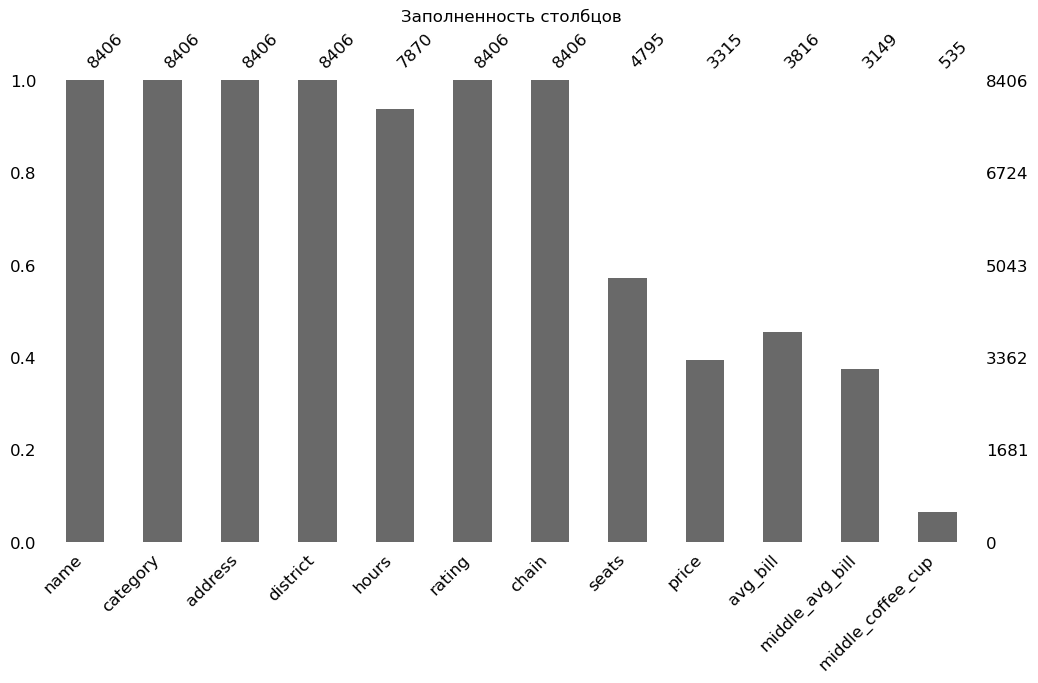

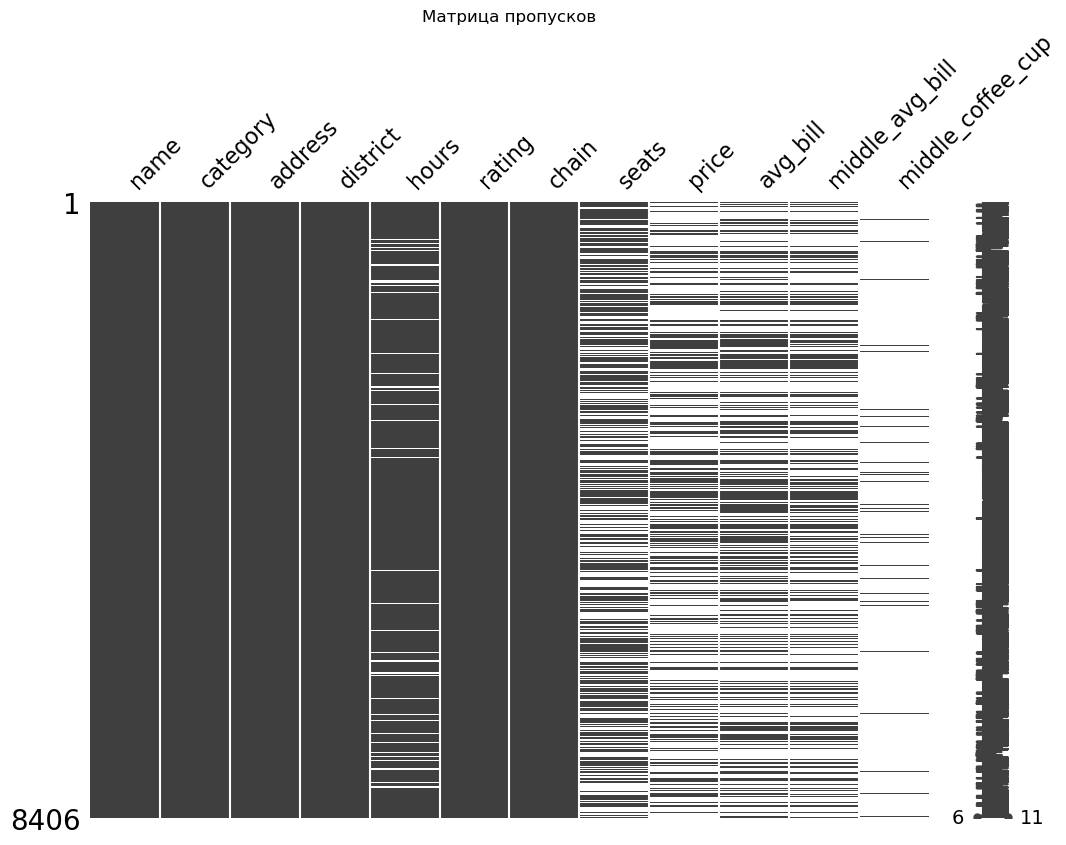

In [25]:
# Строим графики по пропускам
# Обзор долей пропусков
msno.bar(df_rest_merge, figsize=(12, 6), fontsize=12)
plt.title("Заполненность столбцов")

fname_png = "skip_bar.png"
fname_pdf = "skip_bar.pdf"
plt.savefig(png_dir / fname_png, dpi=300, bbox_inches='tight', pad_inches=0.1)
plt.savefig(pdf_dir / fname_pdf, bbox_inches='tight', pad_inches=0.1)

plt.show()

# Матрица
msno.matrix(df_rest_merge, figsize=(12, 8), sparkline=True)
plt.title("Матрица пропусков")

fname_png = "skip_matrix.png"
fname_pdf = "skip_matrix.pdf"
plt.savefig(png_dir / fname_png, dpi=300, bbox_inches='tight', pad_inches=0.1)
plt.savefig(pdf_dir / fname_pdf, bbox_inches='tight', pad_inches=0.1)

plt.show()

Рассмотрим пропуски в столбце `middle_coffee_cup` - 7871 шт.,почти 94%.

In [26]:
# Узнаем в каких категориях заведений присутствует цена за чашку кофе
df_rest_merge[df_rest_merge['middle_coffee_cup'].notna()]['category'].value_counts()

кофейня            521
бар,паб              6
кафе                 4
пиццерия             3
быстрое питание      1
Name: category, dtype: int64

Цена за чашку кофе указана преимущественно в заведениях категории „кофейня“ (521 заведение). В остальных категориях эта информация встречается крайне редко.

Рассмотрим пропуски в столбце `middle_avg_bill` - 5257 шт., почти 63%.

In [27]:
# Узнаем связано ли, что данные по среднему чеку удалось получить из столбца 'avg_bill'
df_rest_merge[df_rest_merge['middle_avg_bill'].notna()][['category','avg_bill', 'middle_avg_bill']].sample(10)

,category,avg_bill,middle_avg_bill
id,,,
eb7fac38923d45068eb3b4d49689ff78,ресторан,Средний счёт:300–500 ₽,400.0
2b27a1031fca41bdb6b7fd917b2bec7b,ресторан,Средний счёт:600–1000 ₽,800.0
de89122680e54ea88325ecd427884767,ресторан,Средний счёт:700–1200 ₽,950.0
209e38ecc7a0418b815343ac51531f62,столовая,Средний счёт:250 ₽,250.0
fbf22d98b62a47fbb2a71be3545f16b2,ресторан,Средний счёт:1500–2000 ₽,1750.0
64dc05879e1a455985bf9d1bc29f1e09,ресторан,Средний счёт:3000–3500 ₽,3250.0
5e2d1536eb6f4fbb902eafcab850084f,ресторан,Средний счёт:1000 ₽,1000.0
17ec4d4bd52d42d4be0ca2906dbc794f,кафе,Средний счёт:300–1500 ₽,900.0
7974626d743048c9a90d68f5512f6e61,кафе,Средний счёт:150–250 ₽,200.0


Значения в столбце `middle_avg_bill` есть только у тех заведений, для которых указан средний чек; при этом такие данные встречаются в разных категориях заведений.

В столбцах `price` и `avg_bill` зафиксировано значительное количество пропусков — 5091 запись (61 %) и 4590 записей (55 %) соответственно. При этом в текущем датасете отсутствуют признаки, позволяющие обоснованно восстановить эти значения.

Рассмотрим пропуски в столбце `seats` - 3611 шт., 43%.

In [28]:
# Узнаем в каких категориях заведений присутствуют значения 'seats'
df_rest_merge[df_rest_merge['seats'].notna()][['category', 'seats']].sample(10)

,category,seats
id,,
00d47c3bc9624a1d93ac63fff64a4ce8,кафе,46.0
b2b6791694454feb85418120a1110550,кафе,60.0
69e94d7442bf4e1380e1d482e82eb073,кафе,50.0
c9fcd0b769da40a68186a7faad94019d,быстрое питание,97.0
6f3a36c44b0840ebb15878688d867e56,кафе,90.0
f9a5eaf1d4b54726b40b6d573736ec84,кафе,200.0
497b2e202c7e4fc8af5cd2fd8a0baf61,пиццерия,180.0
f2dd877f8a454862aa1dd3d4fb9a01eb,ресторан,79.0
2f913b7a99a740478014990f5a7a32d8,кафе,140.0


Количество посадочных мест существенно зависит от категории заведения.

Рассмотрим пропуски в столбце `hours` - 536 шт., 6.4%.

In [29]:
# Выведим 10 случайных 'NaN' строк из столбца 'hours'
df_rest_merge[df_rest_merge['hours'].isna()].sample(10)

,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
id,,,,,,,,,,,,
ce4f2ff0665d4f66938a41fd25b4bf5f,Китайский ресторан,ресторан,"Москва, Волгоградский проспект, 47",ЮВАО,NaN,4.2,1,NaN,NaN,NaN,NaN,NaN
8147b0f2891943cabfddfc658991d467,Кировоградская улица дом 16 корпус 1,кафе,"Москва, Кировоградская улица, 16, корп. 1",ЮАО,NaN,3.7,0,250.0,NaN,NaN,NaN,NaN
bbc3e663a85e433ea5254df97d9c470f,Берег,кафе,"Москва, МКАД, 14-й километр, 2, стр. 55",ЮВАО,NaN,4.9,0,NaN,NaN,NaN,NaN,NaN
0735379c21ef4213bf40715b032eae09,Донер & Гриль,быстрое питание,"Москва, улица Борисовские Пруды, 8, корп. 3",ЮАО,NaN,3.9,0,200.0,NaN,NaN,NaN,NaN
91101226eedc4c08a5e90cd93f53716c,Восточная кухня,кафе,"Москва, Волоколамское шоссе, 116, стр. 1",СЗАО,NaN,3.7,1,320.0,NaN,NaN,NaN,NaN
50b0a34f89564da5b2570520e53b3b2f,Хаиям,кафе,"Москва, МКАД, 19-й километр, вл20с1",ЮАО,NaN,4.9,0,NaN,NaN,NaN,NaN,NaN
8843ecda2246439c89c77c0556e7b234,Русский ресторан,ресторан,"Москва, Преображенская улица, 2, корп. 1",ВАО,NaN,3.5,0,NaN,NaN,NaN,NaN,NaN
5bde318f6ac043c182a34b48231684dd,Абрамово,кафе,"Москва, Окружной проезд, 6, стр. 2",ВАО,NaN,3.9,0,NaN,NaN,NaN,NaN,NaN
468c1eaf26f544d288b6fb1056972d36,Кафе,кафе,"Москва, улица Золоторожский Вал, 32, стр. 6",ЮВАО,NaN,3.3,0,NaN,NaN,NaN,NaN,NaN


В имеющемся датасете отсутствуют признаки, позволяющие обоснованно восстановить пропущенные значения в столбце hours (график работы).

Удаление строк с пропусками в исследованных столбцах не рекомендуется: это существенно сократит объём выборки и может привести к смещению результатов анализа.

<a id='int_conc_missing_values'></a>

#### Промежуточные выводы по наличию пропусков в данных

После объединения датасетов в `df_rest_merge` была проведена проверка пропущенных значений. Результаты представлены в таблице:

| Столбец | Количество пропусков | Доля от всех строк |
|---------|----------------------|---------------------|
| `hours` | 536 | 6.38% |
| `seats` | 3611 | 42.96% |
| `price` | 5091 | 60.56% |
| `avg_bill` | 4590 | 54.60% |
| `middle_avg_bill` | 5257 | 62.54% |
| `middle_coffee_cup` | 7871 | 93.64% |

Столбцы `name`, `category`, `address`, `district`, `rating`, `chain` пропусков не содержат.

**Анализ причин пропусков:**

- **`hours`** — пропущено 536 значений (6.38%). Вероятно, для части заведений режим работы не указан в источнике. Это умеренная доля, и при необходимости строки можно удалить.
- **`seats`** — пропущено 3611 значений (42.96%). Почти половина заведений не имеет данных о количестве посадочных мест. Это может быть связано с тем, что для некоторых форматов (кофейни, быстрое питание, заведения с собой) количество мест не указано или не актуально.
- **`price`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup`** — пропуски составляют от 54.60% до 93.64%. Причина в том, что исходный датасет `rest_price.csv` содержал информацию только по 4058 заведениям, а после левого объединения с `df_rest` (8406 строк) пропуски появились для заведений, по которым ценовых данных не было. Особенно выделяется `middle_coffee_cup` (93.64% пропусков), так как цена чашки капучино указана преимущественно для кофеен.

**Обработка пропусков**

Удаление строк с пропусками в ключевых столбцах признано нецелесообразным: при высокой доле отсутствующих значений (до 61 % в отдельных признаках) это существенно сократит выборку и может внести систематическое смещение в результаты.

[Вернуться к разделу 'Изучение и предобработка данных'](#data_pre)

[Вернуться в начало](#beginning)

<a id='correct_type_data'></a>

### Корректировка типа данных

Для оптимизации возможно применение числовых типов с уменьшенной разрядностью

In [30]:
# Преобразовываем типы данных с понижением разрядности
for col in ['middle_avg_bill', 'middle_coffee_cup', 'rating']:
    df_rest_merge[col] = pd.to_numeric(df_rest_merge[col], downcast='float')

При преобразовании типов в данных столбцах код ошибок не выявил.

In [31]:
# Преобразовываем типы данных с понижением разрядности
for col in ['middle_avg_bill', 'middle_coffee_cup', 'rating']:
    df_rest_merge[col] = df_rest_merge[col].astype('float32')

Столбец `seats` не был преобразован по причине возникновение ошибок (inf) в расчетах среднего и отклонения.

In [32]:
# Преобразовываем типы данных с понижением разрядности
for col in ['chain']:
    df_rest_merge[col] = pd.to_numeric(df_rest_merge[col], downcast='integer')

In [33]:
# Выводим информацию о датафрейме df_rest_merge
df_rest_merge.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8406 entries, 0c3e3439a8c64ea5bf6ecd6ca6ae19f0 to 9d56f8f7a7f74df1a925bc0fd2de8aae
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               8406 non-null   object 
 1   category           8406 non-null   object 
 2   address            8406 non-null   object 
 3   district           8406 non-null   object 
 4   hours              7870 non-null   object 
 5   rating             8406 non-null   float32
 6   chain              8406 non-null   int8   
 7   seats              4795 non-null   float64
 8   price              3315 non-null   object 
 9   avg_bill           3816 non-null   object 
 10  middle_avg_bill    3149 non-null   float32
 11  middle_coffee_cup  535 non-null    float32
dtypes: float32(3), float64(1), int8(1), object(7)
memory usage: 955.8+ KB


Типы данных скорректированы.

[Вернуться к разделу 'Изучение и предобработка данных'](#data_pre)

[Вернуться в начало](#beginning)

<a id='duplicate_in_data'></a>

### Дубликаты в данных

In [34]:
df_rest_merge.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8406 entries, 0c3e3439a8c64ea5bf6ecd6ca6ae19f0 to 9d56f8f7a7f74df1a925bc0fd2de8aae
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               8406 non-null   object 
 1   category           8406 non-null   object 
 2   address            8406 non-null   object 
 3   district           8406 non-null   object 
 4   hours              7870 non-null   object 
 5   rating             8406 non-null   float32
 6   chain              8406 non-null   int8   
 7   seats              4795 non-null   float64
 8   price              3315 non-null   object 
 9   avg_bill           3816 non-null   object 
 10  middle_avg_bill    3149 non-null   float32
 11  middle_coffee_cup  535 non-null    float32
dtypes: float32(3), float64(1), int8(1), object(7)
memory usage: 955.8+ KB


In [35]:
# Выводим количество дубликатов по всему датафрейму
df_rest_merge.duplicated().sum()

0

По всему датафрейму дубликатов нет.

Для выявления повторяющихся записей планируется провести проверку на дубликаты по столбцам `name` и `address`.

In [36]:
# Переводим значения столбцов 'name', 'address' в нижний регистр.
cols = ['name', 'address']
for col in cols:
    df_rest_merge[col] = df_rest_merge[col].str.lower().str.strip()

In [37]:
# Выводим количество найденных дубликатов
subset_cols = ['name', 'address']
df_rest_merge.duplicated(subset=subset_cols).sum()

4

In [38]:
# Выводим строки-дубликаты
df_rest_merge[df_rest_merge.duplicated(subset=subset_cols, keep=False)]

,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
id,,,,,,,,,,,,
072032ce16dc47bfbc63b672c75bd371,кафе,кафе,"москва, парк ангарские пруды",САО,"ежедневно, 09:00–23:00",3.2,0,NaN,NaN,NaN,NaN,NaN
897ddbc6746c4388b19dc8a9fcdbb488,кафе,кафе,"москва, парк ангарские пруды",САО,"ежедневно, 10:00–22:00",3.2,0,NaN,NaN,NaN,NaN,NaN
62608690e9cc464fbcd980cfd552e334,more poke,ресторан,"москва, волоколамское шоссе, 11, стр. 2",САО,"ежедневно, 09:00–21:00",4.2,0,188.0,NaN,NaN,NaN,NaN
a69f018d5c064873a3b491b0121bc1b4,more poke,ресторан,"москва, волоколамское шоссе, 11, стр. 2",САО,"пн-чт 09:00–18:00; пт,сб 09:00–21:00; вс 09:00...",4.2,1,188.0,NaN,NaN,NaN,NaN
c6ef39ae8a8c483d8f9a6531bc386a2c,раковарня клешни и хвосты,ресторан,"москва, проспект мира, 118",СВАО,"ежедневно, 12:00–00:00",4.4,0,150.0,NaN,NaN,NaN,NaN
aba1de7ad7d64ac0a3f8684bda29d905,раковарня клешни и хвосты,"бар,паб","москва, проспект мира, 118",СВАО,"пн-чт 12:00–00:00; пт,сб 12:00–01:00; вс 12:00...",4.4,1,150.0,NaN,NaN,NaN,NaN
3c2a73ea79a04be48858fab3685f2f37,хлеб да выпечка,булочная,"москва, ярцевская улица, 19",ЗАО,"ежедневно, 09:00–22:00",4.1,1,276.0,NaN,NaN,NaN,NaN
d3116844e4e048f99614eb30be3214e0,хлеб да выпечка,кафе,"москва, ярцевская улица, 19",ЗАО,NaN,4.1,0,276.0,NaN,NaN,NaN,NaN


In [39]:
# Изучаем первый дубликат
idxs = ['072032ce16dc47bfbc63b672c75bd371', '897ddbc6746c4388b19dc8a9fcdbb488']

Строки одинаковы. Можно удалять любую. Удалим idx = '897ddbc6746c4388b19dc8a9fcdbb488'

In [40]:
# Изучаем второй дубликат
idxs = ['62608690e9cc464fbcd980cfd552e334', 'a69f018d5c064873a3b491b0121bc1b4']

Строки различны.

In [41]:
# Выводим строки, где встречает название 'more poke'
value = 'more poke'
df_rest_merge[df_rest_merge['name'] == value]

,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
id,,,,,,,,,,,,
62608690e9cc464fbcd980cfd552e334,more poke,ресторан,"москва, волоколамское шоссе, 11, стр. 2",САО,"ежедневно, 09:00–21:00",4.2,0,188.0,NaN,NaN,NaN,NaN
a69f018d5c064873a3b491b0121bc1b4,more poke,ресторан,"москва, волоколамское шоссе, 11, стр. 2",САО,"пн-чт 09:00–18:00; пт,сб 09:00–21:00; вс 09:00...",4.2,1,188.0,NaN,NaN,NaN,NaN
1cd73aca53414d65a7744da3d1c93832,more poke,ресторан,"москва, духовской переулок, 19",ЮАО,"ежедневно, 10:00–22:00",4.4,1,NaN,NaN,NaN,NaN,NaN


Строку с idx = '62608690e9cc464fbcd980cfd552e334' удаляем. В данной строке меньше описание в 'hours' и название 'more poke' встречается чаще с пометкой 1 в столбце 'chain'.

In [42]:
# Изучаем третий дубликат
idxs = ['62608690e9cc464fbcd980cfd552e334', 'a69f018d5c064873a3b491b0121bc1b4']

In [43]:
# Выводим строки, где встречает название 'раковарня клешни и хвосты'
value = 'раковарня клешни и хвосты'
df_rest_merge[df_rest_merge['name'] == value]

,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
id,,,,,,,,,,,,
c6ef39ae8a8c483d8f9a6531bc386a2c,раковарня клешни и хвосты,ресторан,"москва, проспект мира, 118",СВАО,"ежедневно, 12:00–00:00",4.4,0,150.0,NaN,NaN,NaN,NaN
aba1de7ad7d64ac0a3f8684bda29d905,раковарня клешни и хвосты,"бар,паб","москва, проспект мира, 118",СВАО,"пн-чт 12:00–00:00; пт,сб 12:00–01:00; вс 12:00...",4.4,1,150.0,NaN,NaN,NaN,NaN
f2e3eb711fe040c3a2c03e18a6783b05,раковарня клешни и хвосты,"бар,паб","москва, братиславская улица, 12",ЮВАО,"пн-чт 12:00–00:00; пт,сб 12:00–01:00; вс 12:00...",4.9,1,40.0,средние,Цена бокала пива:150–250 ₽,NaN,NaN


Строку с idx = 'c6ef39ae8a8c483d8f9a6531bc386a2c' удаляем по идентичной логики со вторым дубликатом. Так же категория 'бар,паб' встречается немного чаще. 

In [44]:
# Изучаем четвертый дубликат
idxs = ['3c2a73ea79a04be48858fab3685f2f37', 'd3116844e4e048f99614eb30be3214e0']

In [45]:
# Выводим строки, где встречает название 'хлеб да выпечка'
value = 'хлеб да выпечка'
df_rest_merge[df_rest_merge['name'] == value]

,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
id,,,,,,,,,,,,
3c2a73ea79a04be48858fab3685f2f37,хлеб да выпечка,булочная,"москва, ярцевская улица, 19",ЗАО,"ежедневно, 09:00–22:00",4.1,1,276.0,NaN,NaN,NaN,NaN
d3116844e4e048f99614eb30be3214e0,хлеб да выпечка,кафе,"москва, ярцевская улица, 19",ЗАО,NaN,4.1,0,276.0,NaN,NaN,NaN,NaN
d1bb31bf8e1b45f8a2db20182836e3ac,хлеб да выпечка,кофейня,"москва, каширское шоссе, 61г",ЮАО,"ежедневно, 09:00–22:00",4.5,1,NaN,NaN,NaN,NaN,NaN


Строку с idx = 'd3116844e4e048f99614eb30be3214e0' также удаляем. Отсутствие информации в столбце 'hours'. 

In [46]:
# Удаляем дубликаты
idx_to_drop = [
    '897ddbc6746c4388b19dc8a9fcdbb488',
    '62608690e9cc464fbcd980cfd552e334',
    'c6ef39ae8a8c483d8f9a6531bc386a2c',
    'd3116844e4e048f99614eb30be3214e0'
]
df_rest_merge.drop(index=idx_to_drop, inplace=True)

In [47]:
# Выводим количество найденных дубликатов
subset_cols = ['name', 'address']
df_rest_merge.duplicated(subset=subset_cols).sum()

0

Дубликаты по столбцам 'name', 'address' удалены.

[Вернуться к разделу 'Изучение и предобработка данных'](#data_pre)

[Вернуться в начало](#beginning)

### Добавление столбца `is_24_7`

Булевой столбец будет показывать, работает ли заведение ежедневно или нет.

In [48]:
# Сбрасываем индекс id
df_rest_merge = df_rest_merge.reset_index()

In [49]:
# Выводим информацию по датафрейму df_rest_merge
df_rest_merge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8402 entries, 0 to 8401
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8402 non-null   object 
 1   name               8402 non-null   object 
 2   category           8402 non-null   object 
 3   address            8402 non-null   object 
 4   district           8402 non-null   object 
 5   hours              7867 non-null   object 
 6   rating             8402 non-null   float32
 7   chain              8402 non-null   int8   
 8   seats              4792 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float32
 12  middle_coffee_cup  535 non-null    float32
dtypes: float32(3), float64(1), int8(1), object(8)
memory usage: 697.6+ KB


In [50]:
# Выводим первые 30 строк датафрейма df_rest_merge
df_rest_merge['hours'].head(30)

0                                ежедневно, 10:00–22:00
1                                ежедневно, 10:00–22:00
2     пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...
3                                ежедневно, 09:00–22:00
4                                ежедневно, 10:00–22:00
5                                ежедневно, 10:00–23:00
6                     пн 15:00–04:00; вт-вс 15:00–05:00
7     пн-чт 10:00–22:00; пт,сб 10:00–23:00; вс 10:00...
8                                ежедневно, 10:00–22:00
9                                ежедневно, 12:00–00:00
10                             ежедневно, круглосуточно
11                               ежедневно, 10:00–21:00
12                                    вт-сб 09:00–18:00
13                               ежедневно, 08:00–22:00
14                               ежедневно, 13:00–00:00
15                    пн-пт 08:30–18:30; сб 10:00–20:00
16                               ежедневно, 10:00–23:00
17                             ежедневно, кругло

В данных используется только один вариант записи ежедневного круглосуточного режима работы - `ежедневно, круглосуточно`.

In [51]:
# Создаем новый столбец 'is_24_7'
has_daily = df_rest_merge['hours'].str.contains('ежедневно', na=False)
has_24_7 = df_rest_merge['hours'].str.contains('круглосуточно', na=False)
df_rest_merge['is_24_7'] = has_daily & has_24_7
df_rest_merge['is_24_7'].value_counts()

False    7672
True      730
Name: is_24_7, dtype: int64

#### Выводы по добавление столбца `is_24_7`

| Статус (is_24_7) | Количество заведений | Доля (%) | Описание |
| :--- | :--- | :--- | :--- |
| False | 7672 | 91.19% | Не работают круглосуточно и ежедневно (не 24/7) |
| True | 730 | 8.81% | Работают круглосуточно и ежедневно (24/7) |
| **Всего** | **8402** | **100.00%** | — |

1. **Абсолютное доминирование стандартного режима работы:** 
   Подавляющее большинство заведений — **91.19% (7672 заведения)** — не работают в формате 24/7.

2. **Круглосуточный формат — это ниша:**
   Лишь **8.81% (730 заведений)** работают круглосуточно и ежедневно.

[Вернуться к разделу 'Изучение и предобработка данных'](#data_pre)

[Вернуться в начало](#beginning)

<a id='primary_visualization'></a>

### Первичная визуализация

In [52]:
# Выводим информацию по датафрейму df_rest_merge
df_rest_merge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8402 entries, 0 to 8401
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8402 non-null   object 
 1   name               8402 non-null   object 
 2   category           8402 non-null   object 
 3   address            8402 non-null   object 
 4   district           8402 non-null   object 
 5   hours              7867 non-null   object 
 6   rating             8402 non-null   float32
 7   chain              8402 non-null   int8   
 8   seats              4792 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float32
 12  middle_coffee_cup  535 non-null    float32
 13  is_24_7            8402 non-null   bool   
dtypes: bool(1), float32(3), float64(1), int8(1), object(8)
memory usage: 705.8+ KB


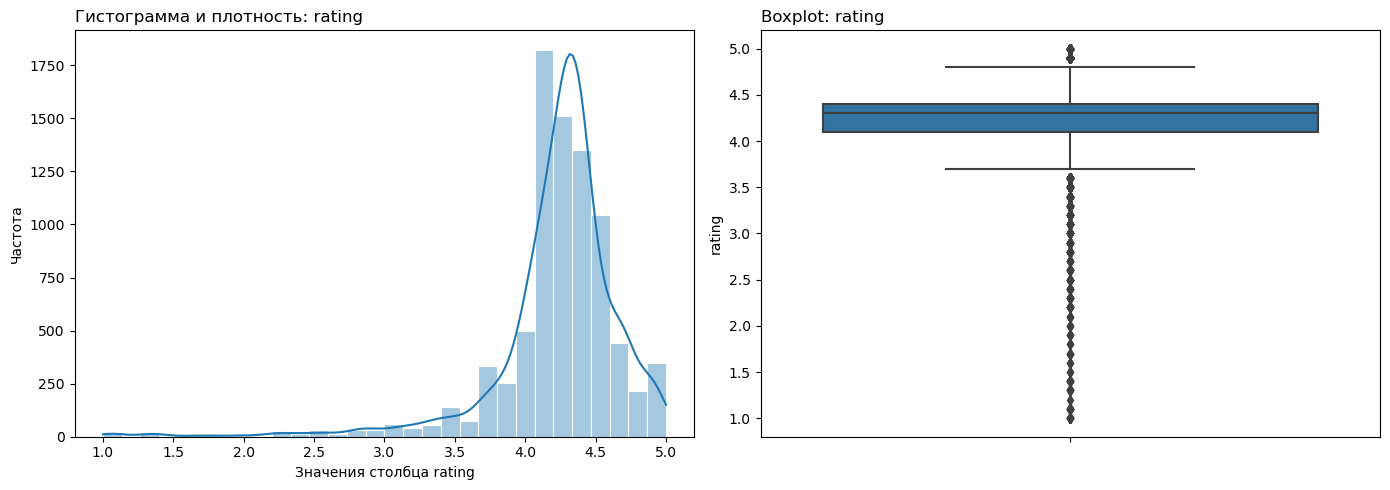

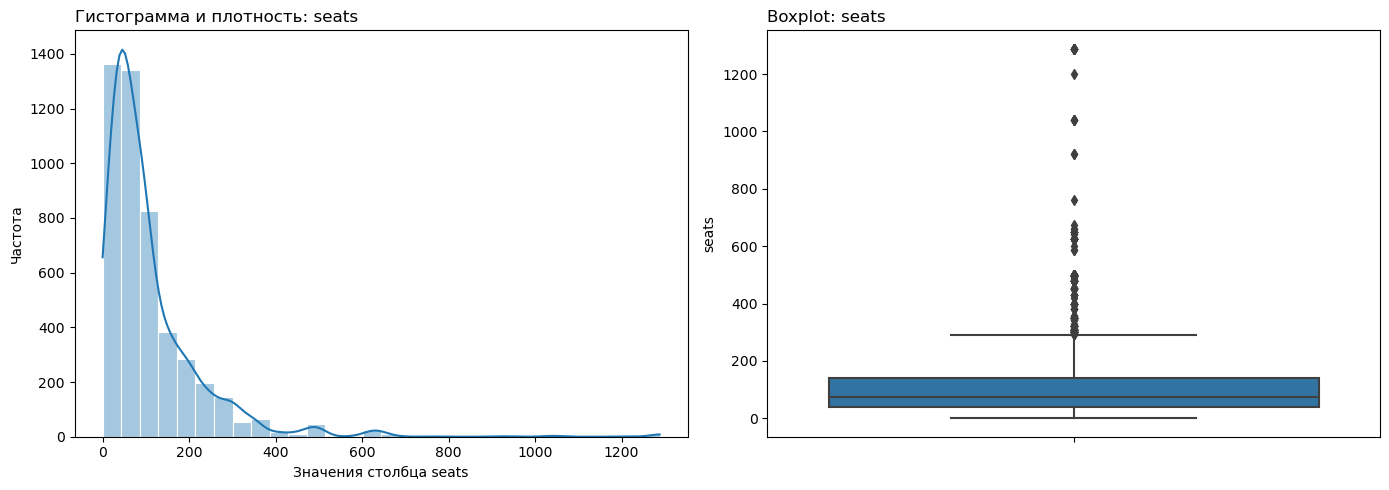

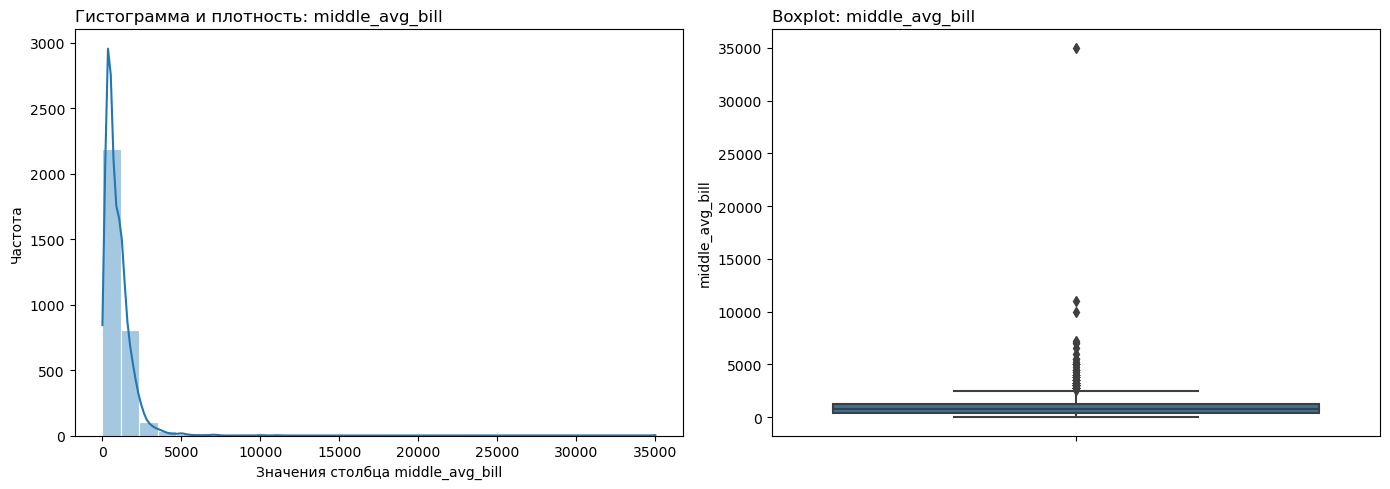

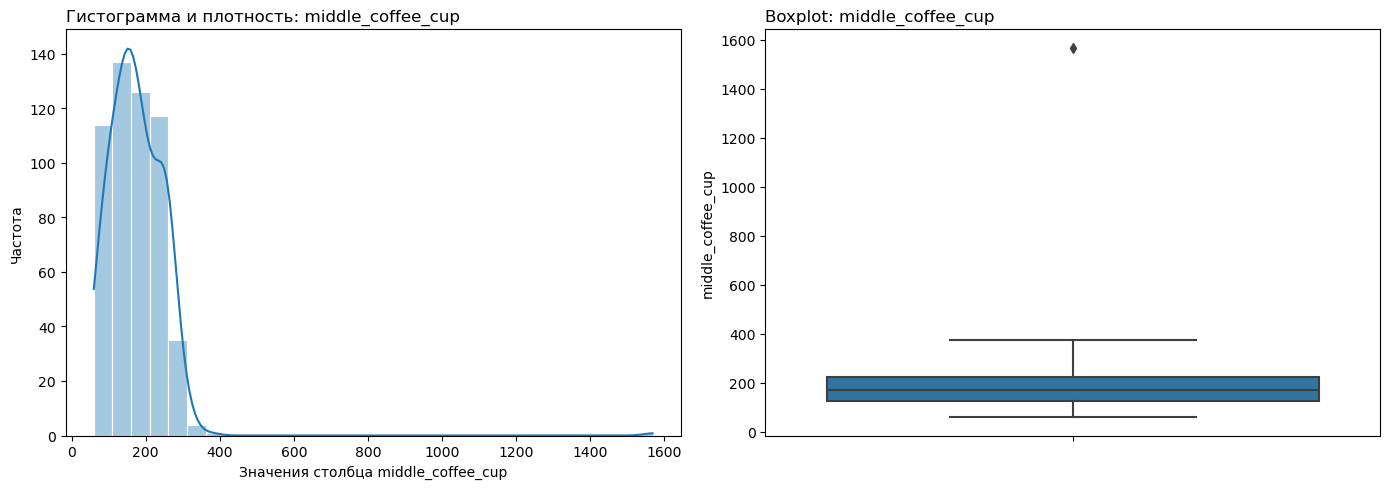

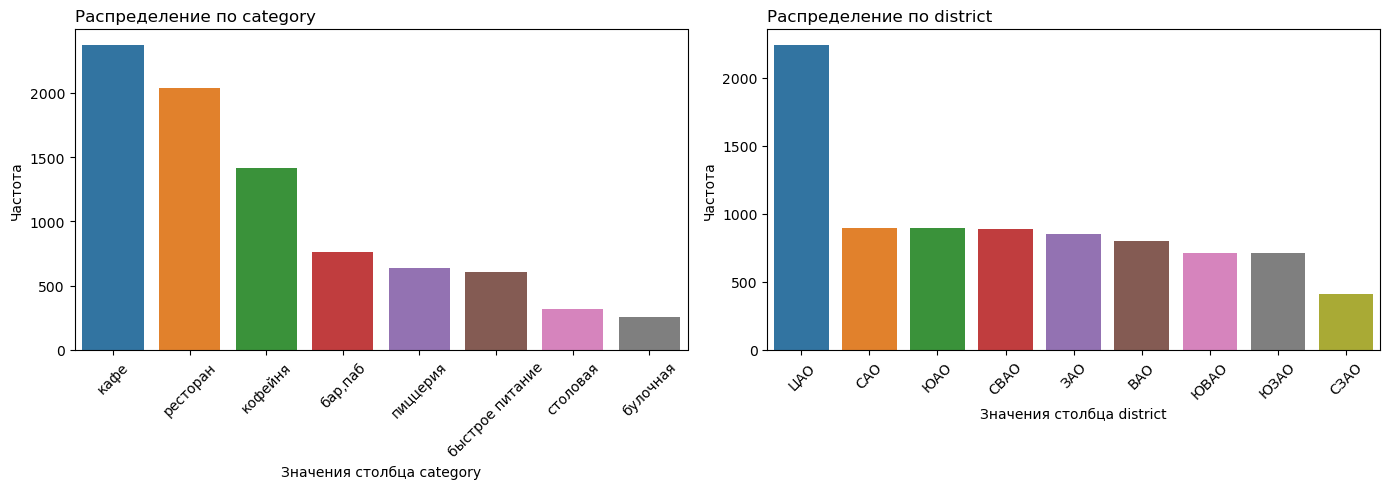

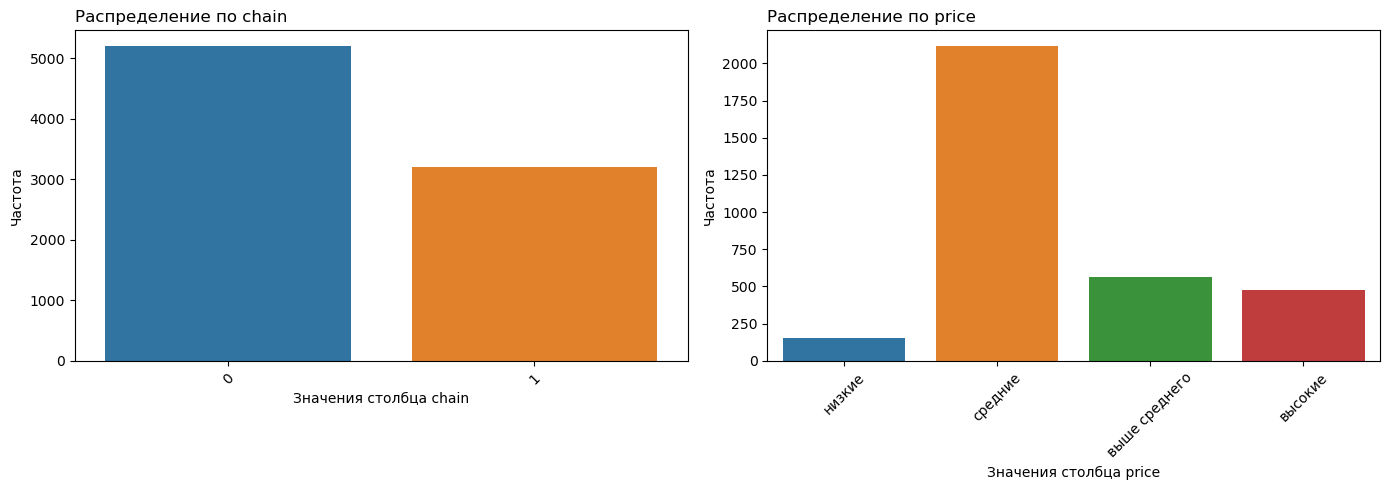

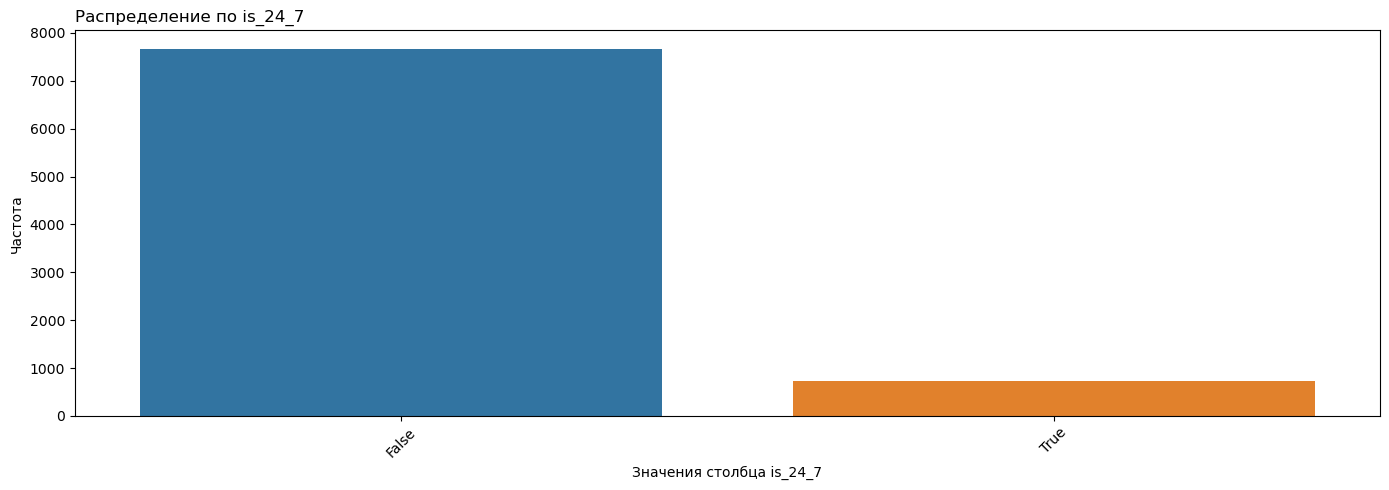

In [53]:
# Создаем графики
df = df_rest_merge.copy()

# Непрерывные признаки: гистограмма + boxplot
cont_cols = ["rating", "seats", "middle_avg_bill", "middle_coffee_cup"]

for col in cont_cols:
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))

    # Гистограмма с KDE
    sns.histplot(data=df, x=col, kde=True, bins=30, ax=axs[0], alpha=0.4, edgecolor='white', linewidth=0.8)
    axs[0].set_title(f"Гистограмма и плотность: {col}", loc="left")
    axs[0].set_xlabel(f"Значения столбца {col}")
    axs[0].set_ylabel("Частота")

    # Боксплот
    sns.boxplot(y=df[col], ax=axs[1])
    axs[1].set_title(f"Boxplot: {col}", loc="left")
    axs[1].set_ylabel(col)

    plt.tight_layout()

    fname_png = f"{col}.png"
    fname_pdf = f"{col}.pdf"

    fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
    fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

    plt.show()
    plt.close(fig)


# Категориальные признаки
cat_cols = [
    "category", "district", "chain",
    "price", "is_24_7"
]

n_cols_in_row = 2 

i = 0
while i < len(cat_cols):
    batch = cat_cols[i:i + n_cols_in_row]
    n_plots = len(batch)

    fig, axs = plt.subplots(1, n_plots, figsize=(14, 5))
    if n_plots == 1:
        axs = [axs]

    for j, col in enumerate(batch):
        ax = axs[j]

        if col == "price":
            col_order = ["низкие", "средние", "выше среднего", "высокие"]
        else:
            col_order = df[col].value_counts().index

        sns.countplot(data=df, x=col, order=col_order, ax=ax)
        ax.set_title(f"Распределение по {col}", loc="left")
        ax.set_xlabel(f"Значения столбца {col}")
        ax.set_ylabel("Частота")
        ax.tick_params(axis="x", labelrotation=45)
        
    plt.tight_layout()

    fname_base = "_".join(batch)
    fname_png = f"{fname_base}.png"
    fname_pdf = f"{fname_base}.pdf"

    fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
    fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

    plt.show()
    plt.close(fig)

    i += n_cols_in_row


<a id='int_conc_primary_visualisation'></a>

#### Промежуточные выводы по первичной визуализации

**1. Категориальные признаки**
*   **Категории заведений (category):** Распределение неравномерное. Лидируют **кафе** (~2300), далее следуют **рестораны** (~2000) и **кофейни** (~1400). Наименее представлены столовые и булочные (менее 400).
*   **Районы (district):** Наблюдается явный дисбаланс. **ЦАО** (Центральный административный округ) значительно превосходит все остальные районы по количеству заведений (более 2000). Остальные районы (САО, ЮАО, СВАО, ЗАО, ВАО, ЮВАО, ЮЗАО, СЗАО) распределены относительно равномерно (от ~700 до ~900 заведений).
*   **Сети (chain):** Независимые заведения (`0`) доминируют над сетевыми (`1`) примерно в соотношении 5:3 (5200 против 3100).
*   **Ценовой сегмент (price):** Рынок ориентирован в основном на **средние цены** (более 2000 заведений). Сегменты "выше среднего" и "высокие" представлены примерно одинаково (~500 каждый), а сегмент "низкие цены" — самый малочисленный (~150).

**2. Бинарные признаки**
*   **Круглосуточная работа (is_24_7):** Подавляющее большинство заведений **не работают круглосуточно** (`False` — ~7700). Круглосуточных заведений (`True`) крайне мало (~700).

**3. Числовые признаки**
*   **Средний чек (middle_avg_bill):** Распределение имеет ярко выраженную правостороннюю асимметрию. Основная масса заведений имеет средний чек от 0 до 2000 (пик в районе 500–1000). Присутствует большое количество выбросов (до 35 000), что говорит о наличии небольшого числа очень дорогих заведений.
*   **Цена за чашку кофе (middle_coffee_cup):** Также правосторонняя асимметрия, но менее выраженная. Большинство значений сосредоточено в диапазоне 100–300 (пик ~150–200). Есть выбросы до ~1600.
*   **Рейтинг (rating):** Распределение с левосторонней асимметрией. Большинство заведений имеют высокие рейтинги (пик в районе 4.2–4.5). Выбросы находятся в нижней части шкалы (от 1.0 до 3.5), что означает, что заведений с низким рейтингом очень мало.
*   **Количество мест (seats):** Сильная правосторонняя асимметрия. Большинство заведений — небольшие, вмещают от 0 до 200 человек (пик ~50–100 мест). Присутствуют значительные выбросы (до ~1300 мест), указывающие на наличие крупных заведений.

[Вернуться к разделу 'Изучение и предобработка данных'](#data_pre)

[Вернуться в начало](#beginning)

<a id='conc_pre_data'></a>

### Выводы по разделу «Изучение и предобработка данных»

1. **Загрузка и объединение данных**
   - Исходный датасет `rest_info.csv` содержит **8406 строк** и **8 столбцов**: `name`, `category`, `address`, `district`, `hours`, `rating`, `chain`, `seats`.
   - Датасет `rest_price.csv` содержит **4058 строк** и **4 столбца**: `price`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup`.
   - После левого объединения по индексу `id` получен `df_rest_merge` с **8406 строками** и **12 столбцами**.

2. **Пропущенные значения**

   - В `df_rest_merge` обнаружены пропуски:

      | Столбец | Пропуски, шт. | Доля |
      |---|---:|---:|
      | `hours` | 536 | 6.38% |
      | `seats` | 3611 | 42.96% |
      | `price` | 5091 | 60.56% |
      | `avg_bill` | 4590 | 54.60% |
      | `middle_avg_bill` | 5257 | 62.54% |
      | `middle_coffee_cup` | 7871 | 93.64% |

   - Пропуски в ценовых признаках объясняются тем, что `rest_price.csv` содержит данные только по части заведений.
   - Пропуски в `seats` связаны с тем, что количество посадочных мест указано не для всех форматов заведений.
   - Удаление строк с пропусками нецелесообразно: это существенно сократит выборку и может привести к смещению результатов анализа.

3. **Дубликаты**
   - Полных дубликатов по всем столбцам нет.
   - По сочетанию `name` + `address` найдено **4 дубликата**.
   - После ручной проверки удалены **4 строки**, итоговый размер выборки — **8402 заведения**.

4. **Корректировка типов данных**
   - `rating`, `middle_avg_bill`, `middle_coffee_cup` приведены к `float32`.
   - `chain` приведён к `int8`.
   - `seats` оставлен в `float64`, так как понижение разрядности приводило к ошибкам (`inf`) при расчёте статистик.

5. **Добавление признака `is_24_7`**
   - Признак показывает, работает ли заведение ежедневно и круглосуточно.
   - Получено:
     | `is_24_7` | Количество | Доля |
     |---|---:|---:|
     | `False` | 7672 | 91.19% |
     | `True` | 730 | 8.81% |
   - Подавляющее большинство заведений **не работают в формате 24/7**.

6. **Первичная визуализация и характер распределений**
   - **Категории:** лидируют кафе — 2376 (28.28%), рестораны — 2041 (24.29%), кофейни — 1413 (16.82%).
   - **Районы:** явный лидер — ЦАО, 2242 заведения (26.68%); минимальная доля — СЗАО, 409 заведений (4.87%).
   - **Сетевой статус:** несетевых заведений 5197 (61.85%), сетевых — 3205 (38.15%).
   - **Ценовые категории:** большинство заведений относятся к среднему ценовому сегменту.
   - **Рейтинг:** распределение смещено вправо; средний рейтинг — 4.23, медиана — 4.30. Большинство заведений имеют высокие оценки.
   - **Посадочные места:** распределение сильно смещено вправо. Медиана — 75 мест, межквартильный диапазон — 40–140, максимум — 1288. Присутствуют выраженные выбросы.
   - **Средний чек и цена чашки кофе:** также имеют правостороннюю асимметрию и выбросы.

7. **Аномальные значения**
   - В `seats` встречается значение `0`, а также значения до `1288` — возможны как крупные заведения, так и ошибки заполнения.
   - В `middle_avg_bill` максимальное значение достигает `35 000`, в `middle_coffee_cup` — `1568`; это выраженные выбросы.
   - Для анализа типичных значений по категориям корректнее использовать **медиану**, а не среднее.

**Общий вывод:**  
Основные проблемы — большое количество пропусков в ценовых признаках и `seats`, а также выраженные выбросы в числовых столбцах. При этом структура данных позволяет провести полноценный исследовательский анализ: выборка достаточная, категориальные признаки заполнены, дубликаты устранены, типы данных скорректированы, добавлен признак круглосуточной работы.

<a id='data_analysis'></a>

## Исследовательский анализ данных

1. [Задача 1. Категории заведений](#task_1) 
    - [Выводы по задаче 1](#conc_task_1)

2. [Задача 2. Административные районы](#task_2)
    - [Выводы по задаче 2](#conc_task_2)

3. [Задача 3. Сетевые/несетевые заведения](#task_3) 
    - [Выводы по задаче 3](#conc_task_3)

4. [Задача 4. Количество посадочных мест](#task_4)
    - [Выводы по задаче 4](#conc_task_4)

5. [Задача 5. Рейтинги заведений](#task_5) 
    - [Выводы по задаче 5](#conc_task_5)

6. [Задача 6. Корреляция рейтингов заведений с прочими данными](#task_6)
    - [Выводы по задаче 6](#conc_task_6)

7. [Задача 7. ТОП-15 популярных сетей в Москве](#task_7) 
    - [Выводы по задаче 7](#conc_task_7)

8. [Задача 8. Вариация среднего чека в зависимости от района Москвы](#task_8)
    - [Выводы по задаче 8](#conc_task_8)

<a id='task_1'></a>

### **Задача 1. Категории заведений**

Какие категории заведений представлены в данных? Исследуйте количество объектов общественного питания по каждой категории. Результат сопроводите подходящей визуализацией.

In [54]:
# Выводим категории заведений
list(df_rest_merge['category'].unique())

['кафе',
 'ресторан',
 'кофейня',
 'пиццерия',
 'бар,паб',
 'быстрое питание',
 'булочная',
 'столовая']

In [55]:
# Расчитываем количество и долю заведений по каждой категории
cat_cnt = df_rest_merge['category'].value_counts(ascending=False)
cat_frac = df_rest_merge['category'].value_counts(normalize=True, ascending=False)

df_cat = pd.DataFrame({
    'cat_cnt': cat_cnt,
    'cat_frac': cat_frac
})

file_path = temp_dir / 'df_cat.csv'
df_cat.reset_index().to_csv(file_path)

df_cat

,cat_cnt,cat_frac
кафе,2376,0.282790
ресторан,2041,0.242918
кофейня,1413,0.168174
"бар,паб",765,0.091050
пиццерия,633,0.075339
быстрое питание,603,0.071769
столовая,315,0.037491
булочная,256,0.030469


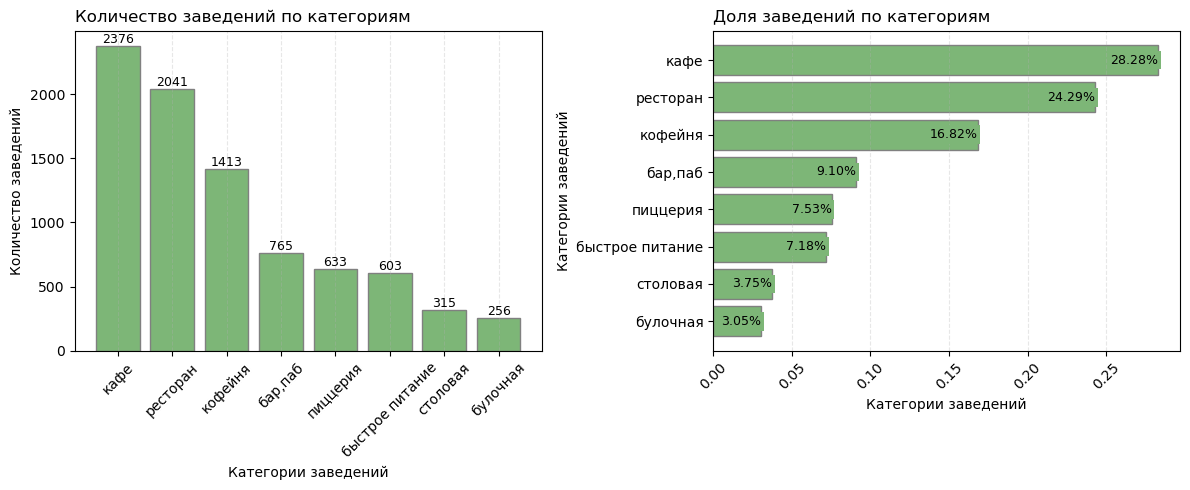

In [56]:
# Строим графики по категориям заведений
cols = ['cat_cnt', 'cat_frac']

titles = {
    'cat_cnt': 'Количество заведений по категориям',
    'cat_frac': 'Доля заведений по категориям'
}
ylabels = {
    'cat_cnt': 'Количество заведений',
    'cat_frac': 'Категории заведений'  # для barh категории идут по Y
}

fig, axs = plt.subplots(1, len(cols), figsize=(12, 5))
if len(cols) == 1:
    axs = [axs]

for ax, col in zip(axs, cols):
    if col == 'cat_cnt':
        agg = df_cat.sort_values(col, ascending=False)[col]
        bars = ax.bar(agg.index, agg.values, color='#7DB677', edgecolor='gray')
        ax.set_xlabel('Категории заведений')
        for bar in bars:
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                height,
                f'{height:.0f}',
                ha='center',
                va='bottom',
                fontsize=9
            )
    else:
        agg = df_cat.sort_values(col, ascending=True)[col]
        bars = ax.barh(agg.index, agg.values, color='#7DB677', edgecolor='gray')
        ax.set_xlabel('Категории заведений')
        for bar in bars:
            width = bar.get_width()
            label_text = f'{width * 100:.2f}%'
            ax.text(
                width,
                bar.get_y() + bar.get_height() / 2,
                label_text,
                ha='right',
                va='center',
                fontsize=9,
                bbox=dict(facecolor='#7DB677', edgecolor='none', pad=2) 
            )
    ax.tick_params(axis='x', labelrotation=45)
    ax.set_title(titles[col], loc='left')
    ax.set_ylabel(ylabels[col])
    ax.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()

fname_base = "_".join(cols)
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()


<a id='conc_task_1'></a>

#### Выводы по задаче 1. Категории заведений

| Категория заведений | Количество (cat_cnt) | Доля (cat_frac) |
|---------------------|----------------------|-----------------|
| кафе                | 2376                 | 28.28%          |
| ресторан            | 2041                 | 24.29%          |
| кофейня             | 1413                 | 16.82%          |
| бар, паб            | 765                  | 9.10%           |
| пиццерия            | 633                  | 7.53%           |
| быстрое питание     | 603                  | 7.18%           |
| столовая            | 315                  | 3.75%           |
| булочная            | 256                  | 3.05%           |
| **Всего**           | **8402**             | **100.00%**     |


*   **Общее количество заведений:** 8402.
*   **Лидирующая категория — кафе:** 2376 заведений (28.28% от общего числа).
*   **Второе место — рестораны:** 2041 заведение (24.29%).
*   **Третье место — кофейни:** 1413 заведений (16.82%).
*   **Топ-3 категории** (кафе, рестораны, кофейни) суммарно занимают **69.39%** всех заведений.
*   **Топ-5 категорий** (добавляются бар/паб и пиццерия) занимают **86.03%**.
*   **Наименьшие доли:**
    *   столовая — 315 заведений (3.75%);
    *   булочная — 256 заведений (3.05%).
*   **Характер распределения:** неравномерный. Большая часть заведений приходится на кафе, рестораны и кофейни. Ниши столовых и булочных представлены слабее всего.

В выборке доминируют заведения типа «кафе», «ресторан» и «кофейня». Именно эти категории являются ключевыми, тогда как столовые и булочные можно рассматривать как менее насыщенные сегменты.

[Вернуться к разделу 'Исследовательский анализ данных'](#data_analysis)

[Вернуться в начало](#beginning)

<a id='task_2'></a>

### **Задача 2. Административные районы**

Какие административные районы Москвы присутствуют в данных? Исследуйте распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы. Результат сопроводите подходящими визуализациями.

In [57]:
# Выводим списко районов Москвы
list(df_rest_merge['district'].unique())

['САО', 'СВАО', 'СЗАО', 'ЗАО', 'ЦАО', 'ВАО', 'ЮВАО', 'ЮАО', 'ЮЗАО']

In [58]:
# Расчитываем количество и долю заведений по каждому району
dist_cnt = df_rest_merge['district'].value_counts(ascending=False)
dist_frac = df_rest_merge['district'].value_counts(normalize=True, ascending=False)

df_dist = pd.DataFrame({
    'dist_cnt': dist_cnt,
    'dist_frac': dist_frac
})

file_path = temp_dir / 'df_dist.csv'
df_dist.reset_index().to_csv(file_path)

df_dist

,dist_cnt,dist_frac
ЦАО,2242,0.266841
САО,898,0.106879
ЮАО,892,0.106165
СВАО,890,0.105927
ЗАО,850,0.101166
ВАО,798,0.094977
ЮВАО,714,0.084980
ЮЗАО,709,0.084385
СЗАО,409,0.048679


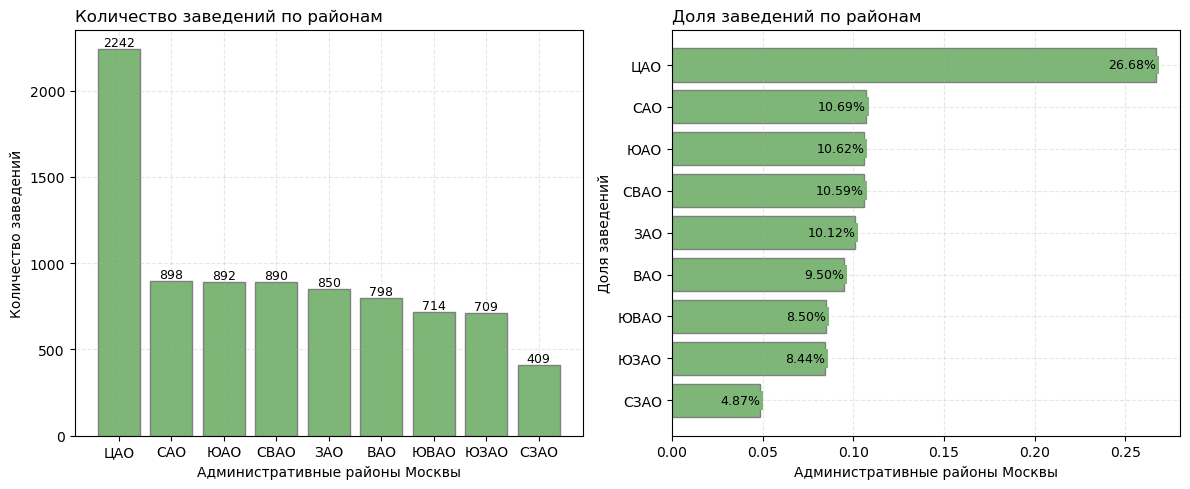

In [59]:
# Строи графики по заведениям в разрезе районов Москвы
cols = ['dist_cnt', 'dist_frac']
titles = {
    'dist_cnt': 'Количество заведений по районам',
    'dist_frac': 'Доля заведений по районам'
}
ylabels = {
    'dist_cnt': 'Количество заведений',
    'dist_frac': 'Доля заведений'
}

fig, axs = plt.subplots(1, len(cols), figsize=(12, 5))
if len(cols) == 1:
    axs = [axs]

for ax, col in zip(axs, cols):
    if col == 'dist_cnt':
        agg = df_dist.sort_values(col, ascending=False)[col]
        bars = ax.bar(agg.index, agg.values, color='#7DB677', edgecolor='gray')
        ax.set_xlabel('Административные районы Москвы')
        for bar in bars:
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                height,
                f'{height:.0f}',
                ha='center',
                va='bottom',
                fontsize=9
            )
    else:
        agg = df_dist.sort_values(col, ascending=True)[col]
        bars = ax.barh(agg.index, agg.values, color='#7DB677', edgecolor='gray')
        ax.set_xlabel('Административные районы Москвы')
        for bar in bars:
            width = bar.get_width()
            label_text = f'{width * 100:.2f}%'
            ax.text(
                width,
                bar.get_y() + bar.get_height() / 2,
                label_text,
                ha='right',
                va='center',
                fontsize=9,
                bbox=dict(facecolor='#7DB677', edgecolor='none', pad=2) 
            )

    ax.set_title(titles[col], loc='left')
    ax.set_ylabel(ylabels[col])
    ax.grid(axis='both', linestyle='--', alpha=0.3)

plt.tight_layout()

fname_base = "_".join(cols)
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()


Исследуем распределение заведений каждой категории в Центральном административном округе Москвы.

In [60]:
# Выводим категории заведений по ЦАО
list(df_rest_merge[df_rest_merge['district'] == 'ЦАО']['category'].unique())

['ресторан',
 'кофейня',
 'бар,паб',
 'кафе',
 'пиццерия',
 'булочная',
 'быстрое питание',
 'столовая']

In [61]:
# Расчитываем количество и долю заведений по каждой категории в ЦАО
cat_cnt_cad = df_rest_merge[df_rest_merge['district'] == 'ЦАО']['category'].value_counts(ascending=False)
cat_frac_cad = df_rest_merge[df_rest_merge['district'] == 'ЦАО']['category'].value_counts(normalize=True, ascending=False)

df_cat_cad = pd.DataFrame({
    'cat_cnt_cad': cat_cnt_cad,
    'cat_frac_cad': cat_frac_cad
})

file_path = temp_dir / 'df_cat_cad.csv'
df_cat_cad.reset_index().to_csv(file_path)

df_cat_cad

,cat_cnt_cad,cat_frac_cad
ресторан,670,0.298840
кафе,464,0.206958
кофейня,428,0.190901
"бар,паб",364,0.162355
пиццерия,113,0.050401
быстрое питание,87,0.038805
столовая,66,0.029438
булочная,50,0.022302


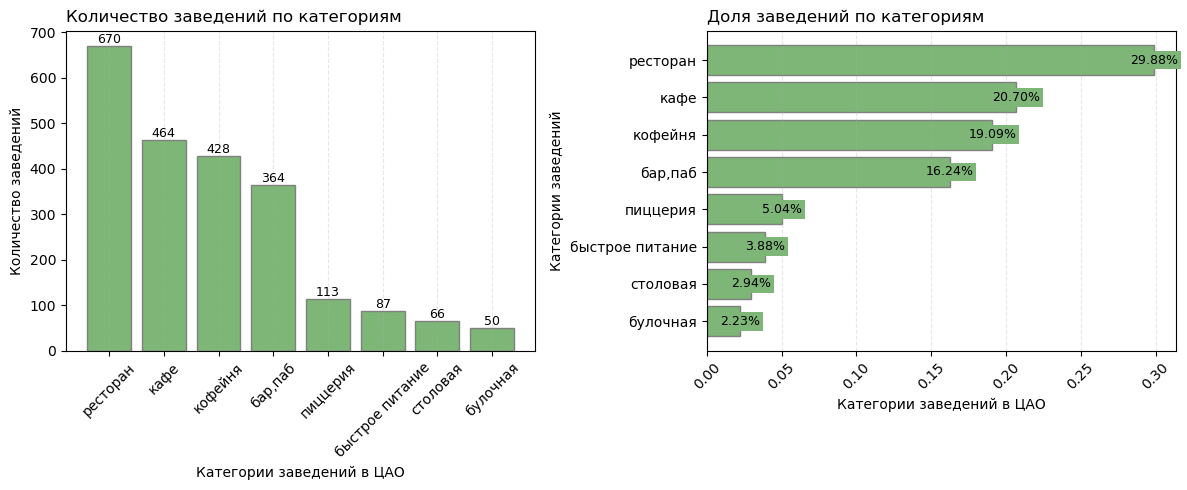

In [62]:
# Строим графики по категориям заведений
cols = ['cat_cnt_cad', 'cat_frac_cad']

titles = {
    'cat_cnt_cad': 'Количество заведений по категориям',
    'cat_frac_cad': 'Доля заведений по категориям'
}
ylabels = {
    'cat_cnt_cad': 'Количество заведений',
    'cat_frac_cad': 'Категории заведений'
}

xlabel = {
    'x_lab':'Категории заведений в ЦАО'
}

fig, axs = plt.subplots(1, len(cols), figsize=(12, 5))
if len(cols) == 1:
    axs = [axs]

for ax, col in zip(axs, cols):
    if col == 'cat_cnt_cad':
        agg = df_cat_cad.sort_values(col, ascending=False)[col]
        bars = ax.bar(agg.index, agg.values, color='#7DB677', edgecolor='gray')
        for bar in bars:
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                height,
                f'{height:.0f}',
                ha='center',
                va='bottom',
                fontsize=9
            )
    else:
        agg = df_cat_cad.sort_values(col, ascending=True)[col]
        bars = ax.barh(agg.index, agg.values, color='#7DB677', edgecolor='gray')
        for bar in bars:
            width = bar.get_width()
            label_text = f'{width * 100:.2f}%'
            ax.text(
                width,
                bar.get_y() + bar.get_height() / 2,
                label_text,
                ha='center',
                va='center',
                fontsize=9,
                bbox=dict(facecolor='#7DB677', edgecolor='none', pad=2) 
            )
    ax.tick_params(axis='x', labelrotation=45)
    ax.set_title(titles[col], loc='left')
    ax.set_ylabel(ylabels[col])
    ax.set_xlabel(xlabel['x_lab'])
    ax.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()

fname_base = "_".join(cols)
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()


<a id='conc_task_2'></a>

#### Выводы по задаче 2. Административные районы

**1. Распределение по районам Москвы**

| Административный район | Количество заведений (dist_cnt) | Доля (dist_frac) |
|------------------------|---------------------------------|------------------|
| ЦАО                    | 2242                            | 26.68%           |
| САО                    | 898                             | 10.69%           |
| ЮАО                    | 892                             | 10.62%           |
| СВАО                   | 890                             | 10.59%           |
| ЗАО                    | 850                             | 10.12%           |
| ВАО                    | 798                             | 9.50%            |
| ЮВАО                   | 714                             | 8.50%            |
| ЮЗАО                   | 709                             | 8.44%            |
| СЗАО                   | 409                             | 4.87%            |
| **Всего**              | **8402**                        | **100.00%**      |

**Выводы по районам:**
*   **Общее количество заведений:** 8402.
*   **Лидер — ЦАО (Центральный административный округ):** 2242 заведения, что составляет **26.68%** от всех заведений города. Это почти в 2.5 раза больше, чем у ближайшего преследователя.
*   **Группа середняков:** Районы САО, ЮАО, СВАО и ЗАО имеют схожие доли — от 10.69% до 10.12%.
*   **Наименьшая доля — СЗАО:** 409 заведений (**4.87%**).
*   Распределение по районам в целом равномерное за исключением двух районов: на ЦАО приходится более четверти всех заведений, в то время как на СЗАО — менее 5%.

**2. Распределение по категориям в ЦАО**

| Категория заведений | Количество (cat_cnt_cad) | Доля (cat_frac_cad) |
|---------------------|--------------------------|---------------------|
| ресторан            | 670                      | 29.88%              |
| кафе                | 464                      | 20.70%              |
| кофейня             | 428                      | 19.09%              |
| бар, паб            | 364                      | 16.24%              |
| пиццерия            | 113                      | 5.04%               |
| быстрое питание     | 87                       | 3.88%               |
| столовая            | 66                       | 2.94%               |
| булочная            | 50                       | 2.23%               |
| **Всего в ЦАО**     | **2242**                 | **100.00%**         |

**Выводы по категориям в ЦАО:**
*   **Смена лидера:** В отличие от общей выборки по городу (где лидировали кафе), в ЦАО на первое место выходят **рестораны** — 670 заведений (**29.88%**).
*   **Второе и третье места:** Кафе (20.70%) и кофейни (19.09%).
*   **Четвертое место:** Бары и пабы (16.24%).
*   **Топ-4 категории** (рестораны, кафе, кофейни, бары/пабы) суммарно занимают **85.91%** всех заведений в ЦАО. ТОП заведений тот же.
*   **Наименьшие доли:** Пиццерии (5.04%), быстрое питание (3.88%), столовые (2.94%) и булочные (2.23%).

[Вернуться к разделу 'Исследовательский анализ данных'](#data_analysis)

[Вернуться в начало](#beginning)

<a id='task_3'></a>

### **Задача 3. Сетевые/несетевые заведения**

Изучите соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения. Каких заведений больше — сетевых или несетевых? Какие категории заведений чаще являются сетевыми? Исследуйте данные, ответьте на вопросы и постройте необходимые визуализации.

In [63]:
# Расчитываем количество и долю заведений по принаддежности к сети
chain_cnt = df_rest_merge['chain'].value_counts(ascending=False)
chain_frac = df_rest_merge['chain'].value_counts(normalize=True, ascending=False)

df_chain = pd.DataFrame({
    'chain_cnt': chain_cnt,
    'chain_frac': chain_frac
})

file_path = temp_dir / 'df_chain.csv'
df_chain.reset_index().to_csv(file_path)

df_chain

,chain_cnt,chain_frac
0,5197,0.618543
1,3205,0.381457


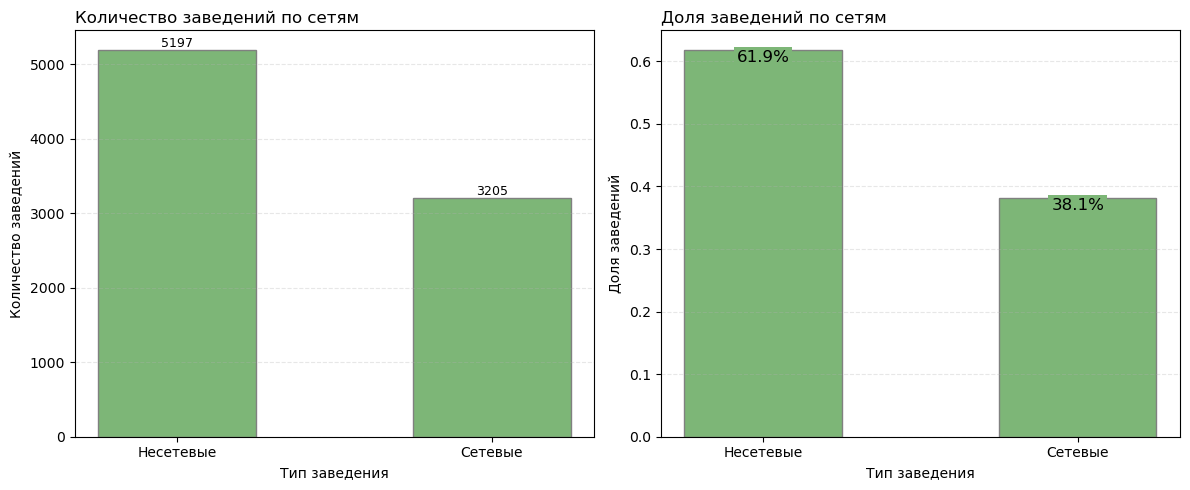

In [64]:
# Строим графики
cols = ['chain_cnt', 'chain_frac']

titles = {
    'chain_cnt': 'Количество заведений по сетям',
    'chain_frac': 'Доля заведений по сетям'
}
ylabels = {
    'chain_cnt': 'Количество заведений',
    'chain_frac': 'Доля заведений'
}
xlabel_text = 'Тип заведения'

fig, axs = plt.subplots(1, len(cols), figsize=(12, 5))
if len(cols) == 1:
    axs = [axs]

for ax, col in zip(axs, cols):
    agg = df_chain.sort_values(col, ascending=False)[col]
    
    bars = ax.bar(agg.index, agg.values, color='#7DB677', edgecolor='gray', width=0.5)
    for bar in bars:
        height = bar.get_height()
        if col == 'chain_cnt':
            label = f'{height:.0f}'
            va = 'bottom'
            fontsize = 9
            bbox = None
        else:
            label = f'{height * 100:.1f}%'
            va = 'top'
            fontsize = 12
            bbox = dict(facecolor='#7DB677', edgecolor='none', pad=2)
        
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            label,
            ha='center',
            va=va,
            fontsize=fontsize,
            bbox=bbox
        )
    
    ax.set_title(titles[col], loc='left')
    ax.set_ylabel(ylabels[col])
    ax.set_xlabel(xlabel_text)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Несетевые', 'Сетевые'])
    
    ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()

fname_base = "_".join(cols)
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()


In [65]:
# Расчитываем количество заведений по сетям в разрезе категорий
df_cat_chain_cnt = df_rest_merge.groupby('chain')['category'].value_counts().unstack().T
df_cat_chain_cnt = df_cat_chain_cnt.sort_values(by=1)

file_path = temp_dir / 'df_cat_chain_cnt.csv'
df_cat_chain_cnt.reset_index().to_csv(file_path)

df_cat_chain_cnt

chain,0,1
category,,
столовая,227,88
булочная,99,157
"бар,паб",596,169
быстрое питание,371,232
пиццерия,303,330
кофейня,693,720
ресторан,1311,730
кафе,1597,779


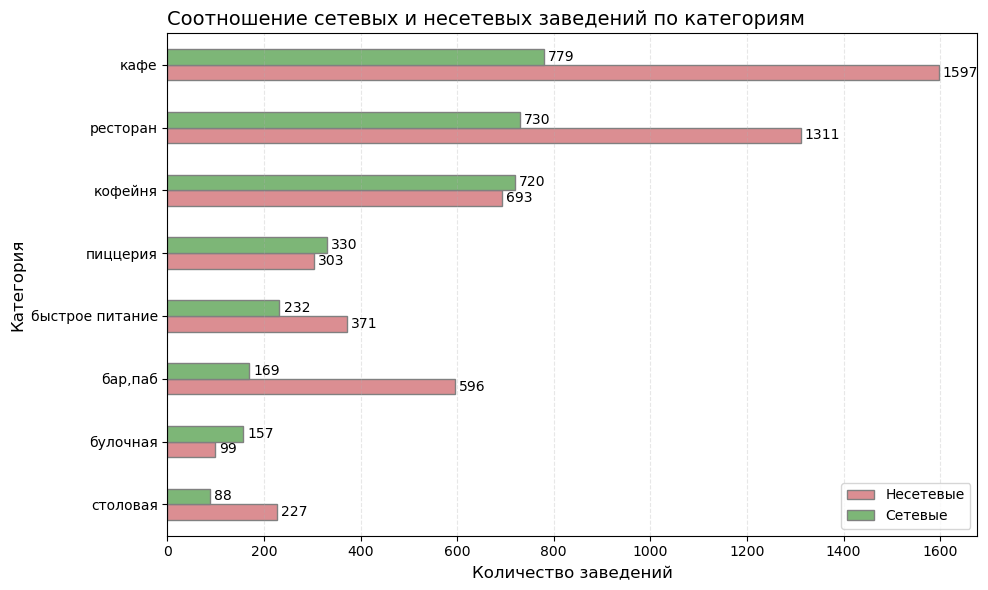

In [66]:
# Строим график
fig, ax = plt.subplots(figsize=(10, 6))

colors = ["#DB8E92", "#7DB677"]

df_cat_chain_cnt.plot(
    kind='barh',
    ax=ax,
    color=colors,
    edgecolor='gray'      
)

ax.set_title('Соотношение сетевых и несетевых заведений по категориям', loc='left', fontsize=14)
ax.set_xlabel('Количество заведений', fontsize=12)
ax.set_ylabel('Категория', fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)
# Matplotlib ниже 3.4.1
#for container in ax.containers:
#    for bar in container:
#        width = bar.get_width()
#        x_pos = width / 2
#        y_pos = bar.get_y() + bar.get_height() / 2
#        ax.text(x_pos, y_pos, f'{width:.2f}, 
#                ha='center', va='center', fontsize=8, color='white', fontweight='bold')

ax.legend(['Несетевые', 'Сетевые'])
ax.grid(axis='x', alpha=0.3, linestyle='--')
plt.tight_layout()

fname_base = 'cat_chain_cnt'
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()

Изучим только сетевые заведения

In [67]:
# Расчитываем количество сетевых заведений в разрезе категорий
cat_chain_1_cnt = df_rest_merge[df_rest_merge['chain'] == 1]['category'].value_counts(ascending=False)
cat_chain_1_frac = df_rest_merge[df_rest_merge['chain'] == 1]['category'].value_counts(normalize=True, ascending=False)

df_cat_chain_1 = pd.DataFrame({
    'cat_chain_1_cnt': cat_chain_1_cnt,
    'cat_chain_1_frac': cat_chain_1_frac
})

file_path = temp_dir / 'df_cat_chain_1.csv'
df_cat_chain_1.reset_index().to_csv(file_path)

df_cat_chain_1

,cat_chain_1_cnt,cat_chain_1_frac
кафе,779,0.243058
ресторан,730,0.227769
кофейня,720,0.224649
пиццерия,330,0.102964
быстрое питание,232,0.072387
"бар,паб",169,0.052730
булочная,157,0.048986
столовая,88,0.027457


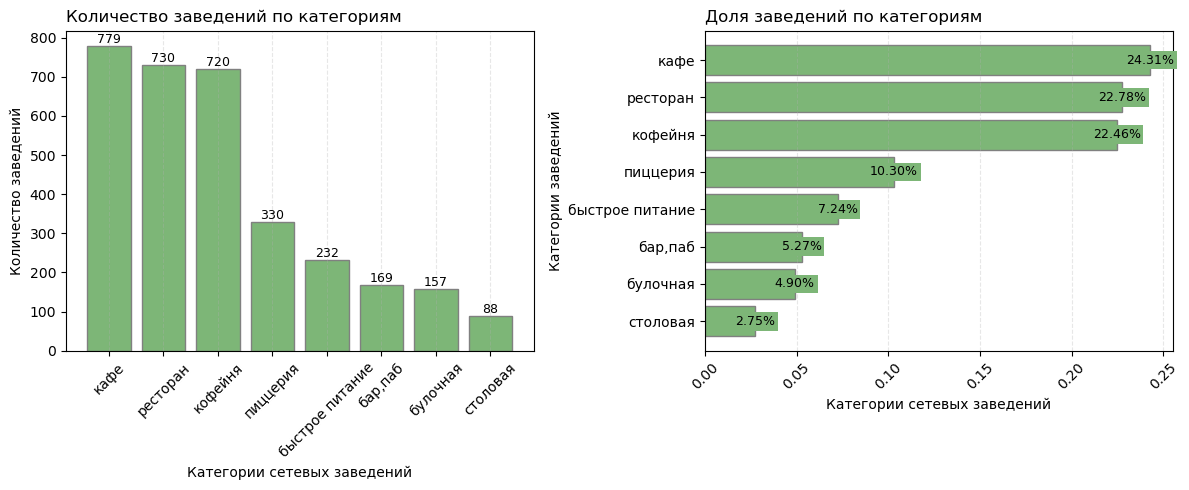

In [68]:
# Строим графики по категориям заведений
cols = ['cat_chain_1_cnt', 'cat_chain_1_frac']

titles = {
    'cat_chain_1_cnt': 'Количество заведений по категориям',
    'cat_chain_1_frac': 'Доля заведений по категориям'
}
ylabels = {
    'cat_chain_1_cnt': 'Количество заведений',
    'cat_chain_1_frac': 'Категории заведений'
}

xlabel = {
    'x_lab':'Категории сетевых заведений'
}

fig, axs = plt.subplots(1, len(cols), figsize=(12, 5))
if len(cols) == 1:
    axs = [axs]

for ax, col in zip(axs, cols):
    if col == 'cat_chain_1_cnt':
        agg = df_cat_chain_1.sort_values(col, ascending=False)[col]
        bars = ax.bar(agg.index, agg.values, color='#7DB677', edgecolor='gray')
        for bar in bars:
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                height,
                f'{height:.0f}',
                ha='center',
                va='bottom',
                fontsize=9
            )
    else:
        agg = df_cat_chain_1.sort_values(col, ascending=True)[col]
        bars = ax.barh(agg.index, agg.values, color='#7DB677', edgecolor='gray')
        for bar in bars:
            width = bar.get_width()
            label_text = f'{width * 100:.2f}%'
            ax.text(
                width,
                bar.get_y() + bar.get_height() / 2,
                label_text,
                ha='center',
                va='center',
                fontsize=9,
                bbox=dict(facecolor='#7DB677', edgecolor='none', pad=2) 
            )
    ax.tick_params(axis='x', labelrotation=45)
    ax.set_title(titles[col], loc='left')
    ax.set_ylabel(ylabels[col])
    ax.set_xlabel(xlabel['x_lab'])
    ax.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()

fname_base = "_".join(cols)
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()


<a id='conc_task_3'></a>

#### Выводы по задаче 3. Сетевые/несетевые заведения

**Общее соотношение по всем данным**

| Тип заведения | Количество | Доля |
|---------------|------------|------|
| **Несетевые** | 5197       | 61.85% |
| **Сетевые**   | 3205       | 38.15% |
| **Всего**     | 8402       | 100.00% |

Несетевых заведений значительно больше — **61.85%** против **38.15%** сетевых. Это означает, что рынок представлен преимущественно несетевыми заведениями.

---
**Соотношение сетевых и несетевых заведений по категориям**

| Категория   | Несетевые (0) | Сетевые (1) | Всего | Доля сетевых в категории |
|-------------|---------------|-------------|-------|--------------------------|
| кафе        | 1597          | 779         | 2376  | 32.79%                   |
| ресторан    | 1311          | 730         | 2041  | 35.77%                   |
| кофейня     | 693           | 720         | 1413  | 50.96%                   |
| бар,паб     | 596           | 169         | 765   | 22.09%                   |
| пиццерия    | 303           | 330         | 633   | 52.13%                   |
| быстрое питание | 371       | 232         | 603   | 38.47%                   |
| столовая    | 227           | 88          | 315   | 27.94%                   |
| булочная    | 99            | 157         | 256   | 61.33%                   |

1. **По абсолютному количеству сетевых заведений** лидируют:
   * **Кафе** — 779 заведений (24.31% от всех сетевых).
   * **Ресторан** — 730 заведений (22.78%).
   * **Кофейня** — 720 заведений (22.46%).
   
   На эти три категории приходится почти **70%** всех сетевых заведений.

2. **По доле сетевых внутри категории** лидируют:
   * **Булочная** — 61.33% (сетевых больше, чем несетевых).
   * **Пиццерия** — 52.13% (сетевых больше, чем несетевых).
   * **Кофейня** — 50.96% (примерно равное соотношение, с небольшим перевесом в сторону сетей).

---

**Выводы**

1. **Общий тренд:** Рынок общественного питания в выборке на 61.85% состоит из несетевых заведений. Сетевой формат уступает независимому бизнесу.
2. **Наиболее «сетевизированные» категории:** Булочные, пиццерии и кофейни. Доля сетей здесь превышает 50%.
3. **Наименее «сетевизированные» категории:** Бары/пабы (22.09%), столовые (27.94%) и кафе (32.79%).
4. **Крупнейшие сети:** В абсолютных цифрах больше всего сетевых точек сосредоточено в категориях «кафе» (779), «ресторан» (730) и «кофейня» (720).
5. **Специфика форматов:** Интересно, что в категории «булочная» сетевых заведений (157) больше, чем несетевых (99), что делает её единственной категорией с явным преобладанием сетей (наряду с пиццериями, где перевес небольшой).

[Вернуться к разделу 'Исследовательский анализ данных'](#data_analysis)

[Вернуться в начало](#beginning)

<a id='task_4'></a>

### **Задача 4. Количество посадочных мест**

Исследуйте количество посадочных мест в заведениях. Встречаются ли в данных аномальные значения или выбросы? Если да, то с чем они могут быть связаны? Приведите для каждой категории заведений наиболее типичное для него количество посадочных мест. Результат сопроводите подходящими визуализациями.

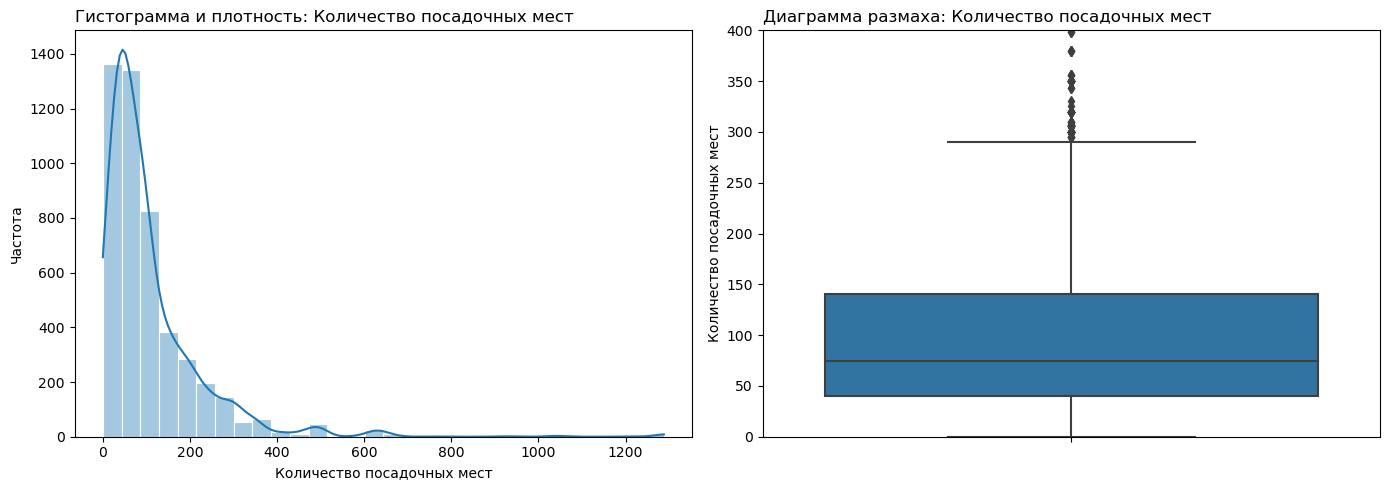

In [69]:
# Создаем графики - гистрограмму и диаграмму размаха
df = df_rest_merge.copy()

col = "seats"

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма с KDE
sns.histplot(data=df, x=col, kde=True, bins=30, ax=axs[0], alpha=0.4, edgecolor='white', linewidth=0.8)
axs[0].set_title(f"Гистограмма и плотность: Количество посадочных мест", loc="left")
axs[0].set_xlabel("Количество посадочных мест")
axs[0].set_ylabel("Частота")

# Боксплот
sns.boxplot(y=df[col], ax=axs[1])
axs[1].set_title("Диаграмма размаха: Количество посадочных мест", loc="left")
axs[1].set_ylabel("Количество посадочных мест")
axs[1].set_ylim(0, 400)

plt.tight_layout()

fname_png = f"{col}.png"
fname_pdf = f"{col}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()
plt.close(fig)

In [70]:
# Выведим основные статистические показатели
df_rest_merge['seats'].describe()

count    4792.000000
mean      108.361436
std       122.841130
min         0.000000
25%        40.000000
50%        75.000000
75%       140.000000
max      1288.000000
Name: seats, dtype: float64

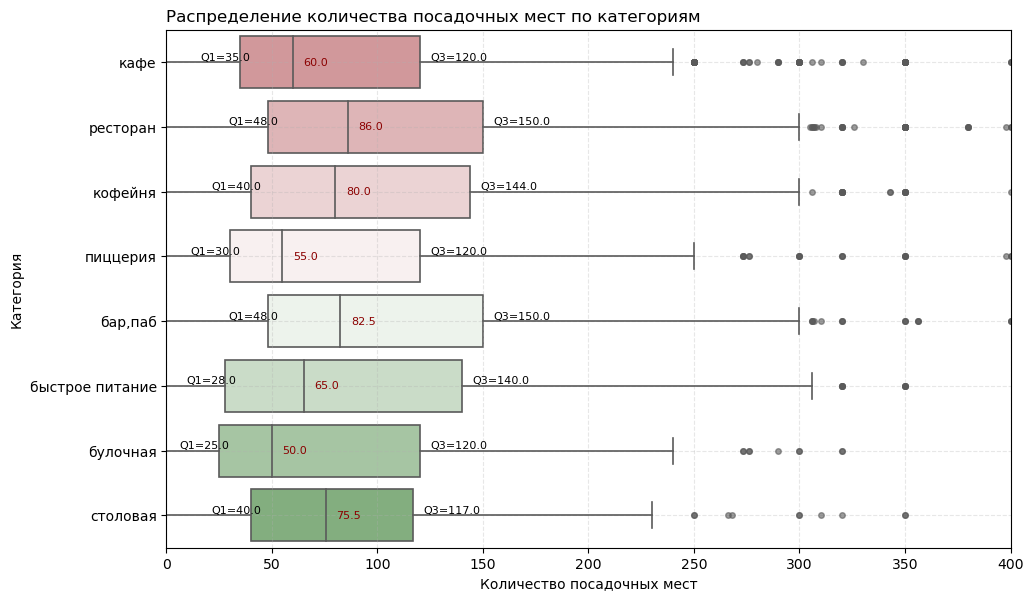

In [71]:
# Построим диаграмму размаха посадочных мест в заведениях с разбивкой по категориям
fig, ax = plt.subplots(figsize=(10, 6))

# Добавляем градиент
categories = df_rest_merge['category'].unique()
n_cats = len(categories)

indices = np.linspace(0, 1, n_cats)
custom_palette = [my_cmap_01(i) for i in indices]

# График
sns.boxplot(
    data=df_rest_merge,
    x='seats',
    y='category',
    ax=ax,
    linewidth=1.2,
    flierprops={
        'marker': 'o', 
        'markersize': 4, 
        'alpha': 0.6
    },
    palette=custom_palette
)

ax.set_title('Распределение количества посадочных мест по категориям', loc='left')
ax.set_xlabel('Количество посадочных мест')
ax.set_ylabel('Категория')
ax.set_xlim(0, 400)
ax.grid(axis='both', alpha=0.3,linestyle='--')

# Добавляем подписи
for i, cat in enumerate(categories):
    s = df_rest_merge[df_rest_merge['category'] == cat]['seats']
    q1, q3 = s.quantile([0.25, 0.75])
    med = s.median()
    mn, mx = s.min(), s.max()

    # Медиана, q1, q3
    ax.text(med + 5, i, f'{med:.1f}', va='center', ha='left', fontsize=8, color='darkred')
    ax.text(q1 + 5, i, f'Q1={q1:.1f}', va='bottom', ha='right', fontsize=8, color='black')
    ax.text(q3 + 5, i, f'Q3={q3:.1f}', va='bottom', ha='left', fontsize=8, color='black')

fname_png = "cat_seats_boxplot.png"
fname_pdf = "cat_seats_boxplot.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.tight_layout()
plt.show()

In [72]:
# Отобразим медианы по категориям заведений в таблице
categories = df_rest_merge['category'].unique()
df_seats = df_rest_merge.groupby('category')['seats'].median().reindex(categories)

file_path = temp_dir / 'df_seats.csv'
df_seats.reset_index().to_csv(file_path)

df_seats

category
кафе               60.0
ресторан           86.0
кофейня            80.0
пиццерия           55.0
бар,паб            82.5
быстрое питание    65.0
булочная           50.0
столовая           75.5
Name: seats, dtype: float64

<a id='conc_task_4'></a>

#### Выводы по задаче 4. Количество посадочных мест

1. **Данные о количестве мест доступны не для всех заведений:** информация представлена по **4792 заведениям**.

2. **Типичное количество посадочных мест — 75:** медианное значение составляет **75 мест**. Это означает, что половина заведений имеет не более 75 мест, а другая половина — не менее 75.

3. **Основной диапазон — от 40 до 140 мест:** половина заведений попадает в интервал **40–140 посадочных мест**, то есть типичный размер заведения находится именно в этих пределах.

4. **Распределение сильно смещено вправо:** присутствуют заведения с очень большим количеством мест — вплоть до **1288**. Такие значения являются выбросами и могут быть связаны как с действительно крупными заведениями, так и с ошибками заполнения данных.

5. **Для сравнения категорий корректнее использовать медиану:** из-за большого количества выбросов среднее значение может искажать картину, поэтому за типичное количество посадочных мест принята **медиана** по каждой категории.

6. **Самые маленькие по типичному размеру — булочные:** наименьшая медиана наблюдается у **булочных** — **50 мест**.

7. **Самые крупные по типичному размеру — рестораны:** наибольшая медиана у **ресторанов** — **86 мест**.

8. **Наиболее крупные форматы по медианному количеству мест:** в целом по типичному числу посадочных мест выделяются **рестораны, бары/пабы и кофейни**.

**Общий вывод:** по доступным данным типичное заведение имеет около **75 посадочных мест**, однако распределение сильно неоднородно. Из-за выраженных выбросов для характеристики типичного размера заведений следует опираться на медиану, а не на среднее. При сравнении категорий наиболее крупными по медиане являются рестораны, бары/пабы и кофейни, а наиболее компактными — булочные.

[Вернуться к разделу 'Исследовательский анализ данных'](#data_analysis)

[Вернуться в начало](#beginning)

<a id='task_5'></a>

### **Задача 5. Рейтинги заведений**

Исследуйте рейтинг заведений. Визуализируйте распределение средних рейтингов по категориям заведений. Сильно ли различаются усреднённые рейтинги для разных типов общепита?

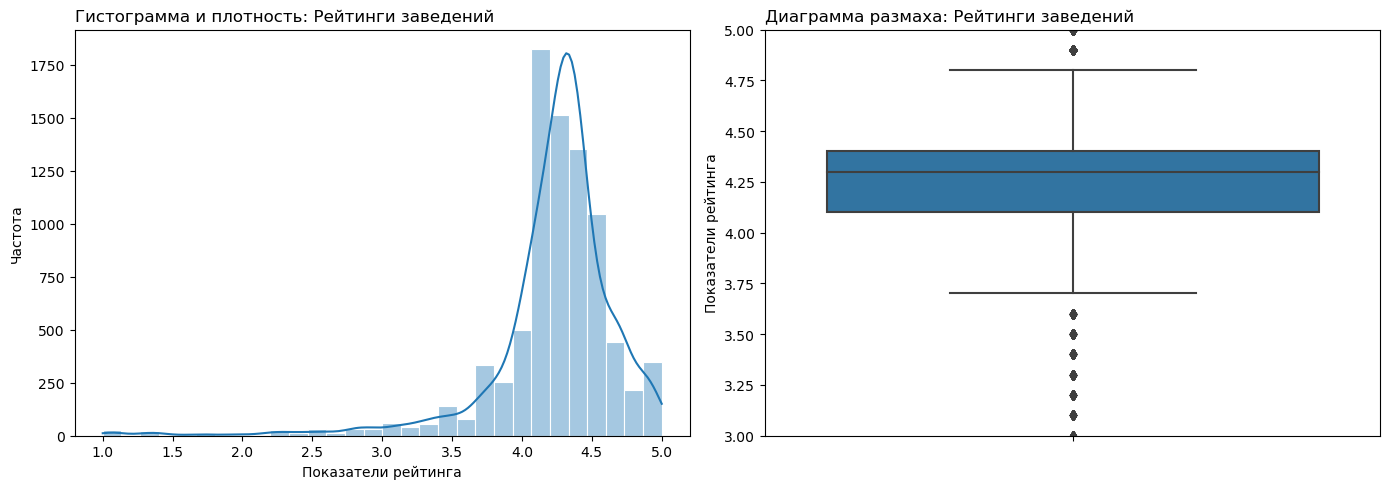

In [73]:
# Создаем графики - гистрограмму и диаграмму размаха
df = df_rest_merge.copy()

col = "rating"

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма с KDE
sns.histplot(data=df, x=col, kde=True, bins=30, ax=axs[0], alpha=0.4, edgecolor='white', linewidth=0.8)
axs[0].set_title(f"Гистограмма и плотность: Рейтинги заведений", loc="left")
axs[0].set_xlabel("Показатели рейтинга")
axs[0].set_ylabel("Частота")

# Боксплот
sns.boxplot(y=df[col], ax=axs[1])
axs[1].set_title("Диаграмма размаха: Рейтинги заведений", loc="left")
axs[1].set_ylabel("Показатели рейтинга")
axs[1].set_ylim(3, 5)

plt.tight_layout()

fname_png = f"{col}.png"
fname_pdf = f"{col}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()
plt.close(fig)

In [74]:
# Выведим основные статистические показатели
df_rest_merge['rating'].describe()

count    8402.000000
mean        4.230016
std         0.470320
min         1.000000
25%         4.100000
50%         4.300000
75%         4.400000
max         5.000000
Name: rating, dtype: float64

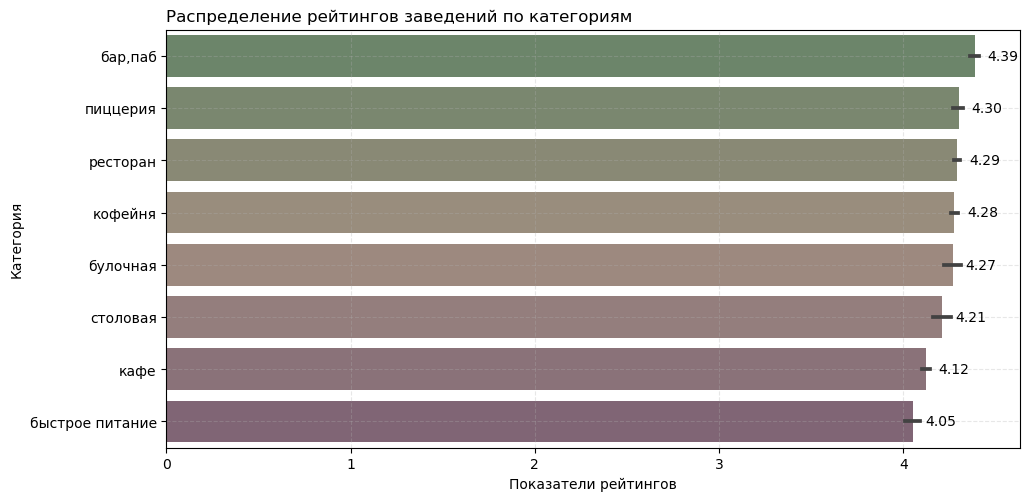

In [75]:
# Считаем средний рейтинг по категориям и сортируем по убыванию
df = (
    df_rest_merge.groupby('category')['rating']
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)

# Построим диаграмму рейтингов заведений с разбивкой по категориям
fig, ax = plt.subplots(figsize=(10, 5))

# Добавляем градиент
n_cats = len(categories)
indices = np.linspace(0, 1, n_cats)
custom_palette = [my_cmap_03(i) for i in indices]

# График
sns.barplot(
    data=df_rest_merge,
    x='rating',
    y='category',
    ax=ax,
    estimator=np.mean,
    palette=custom_palette,
    order=df,
    orient='h'
)

ax.set_title('Распределение рейтингов заведений по категориям', loc='left')
ax.set_xlabel('Показатели рейтингов')
ax.set_ylabel('Категория')
ax.grid(axis='both', alpha=0.3,linestyle='--')

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f',
        padding=9,
        fontsize=10,
        color='black'
    )

fname_png = "cat_rating_barplot.png"
fname_pdf = "cat_rating_barplot.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.tight_layout()
plt.show()


<a id='conc_task_5'></a>

#### Выводы по задаче 5. Рейтинги заведений

1. **Общий уровень рейтингов достаточно высокий:** 
   * Средний рейтинг по всем 8402 заведениям составляет **4.23** балла, а медианный — **4.30**.
   * Большинство заведений имеют оценки в диапазоне от 4.10 до 4.40 балла (межквартильный размах 25%–75%).

2. **Распределение рейтингов смещено в сторону высоких значений:**
   * На гистограмме виден явный пик в районе 4.2–4.4 балла. Подавляющее большинство заведений получили высокие оценки.
   * При этом на диаграмме размаха (boxplot) видны выбросы в нижней части — присутствуют заведения с крайне низкими рейтингами (вплоть до 1.0), однако их доля невелика.

3. **Различия между категориями минимальны:**
   * Разброс средних рейтингов между категориями составляет всего около **0.3 балла**.
   * Все категории демонстрируют стабильно высокие средние показатели — в диапазоне от **4.0 до 4.4** балла.

4. **Лидеры и аутсайдеры по рейтингу:**
   * **Наивысший рейтинг** среди категорий имеют **бары и пабы** — **4.39**.
   * Следом идут пиццерии (4.30), рестораны (4.29), кофейни (4.28) и булочные (4.27). 
   * **Наименьший средний рейтинг** наблюдается у заведений **быстрого питания** — **4.05**, также чуть ниже среднего у кафе (4.12) и столовых (4.21).

**Вывод:** Рынок общественного питания в выборке характеризуется очень высокими оценками. Пользователи в целом благосклонны к заведениям, а разница в качестве обслуживания или продукта между разными категориями (от баров до фастфуда) с точки зрения выставленных рейтингов практически незаметна. Наиболее высоко оцениваются бары/пабы, а заведения быстрого питания замыкают список, хотя их показатель 4.05 все равно остается высоким.

[Вернуться к разделу 'Исследовательский анализ данных'](#data_analysis)

[Вернуться в начало](#beginning)

<a id='task_6'></a>

### **Задача 6. Корреляция рейтингов заведений с прочими данными**

Изучите, с какими данными показывают самую сильную корреляцию рейтинги заведений? Постройте и визуализируйте матрицу корреляции рейтинга заведения с разными данными: его категория, положение (административный район Москвы), статус сетевого заведения, количество мест, ценовая категория и признак, является ли заведения круглосуточным. Выберите самую сильную связь и проверьте её.

In [76]:
# Создадим датафрейм для корреляции
df_corr = df_rest_merge[['category', 'district', 'rating', 'chain', 'seats', 'price', 'is_24_7']].copy()

file_path = temp_dir / 'df_corr.csv'
df_corr.reset_index().to_csv(file_path)

In [77]:
# Создадим матрицу phik
df_corr_matrix = df_corr.phik_matrix()
df_corr_matrix

interval columns not set, guessing: ['rating', 'chain', 'seats']


,category,district,rating,chain,seats,price,is_24_7
category,1.000000,0.174517,0.198763,0.265477,0.048265,0.566933,0.244814
district,0.174517,1.000000,0.189453,0.064447,0.352440,0.202787,0.076357
rating,0.198763,0.189453,1.000000,0.119212,0.000000,0.262056,0.161010
chain,0.265477,0.064447,0.119212,1.000000,0.057584,0.218211,0.043227
seats,0.048265,0.352440,0.000000,0.057584,1.000000,0.088146,0.043193
price,0.566933,0.202787,0.262056,0.218211,0.088146,1.000000,0.084183
is_24_7,0.244814,0.076357,0.161010,0.043227,0.043193,0.084183,1.000000


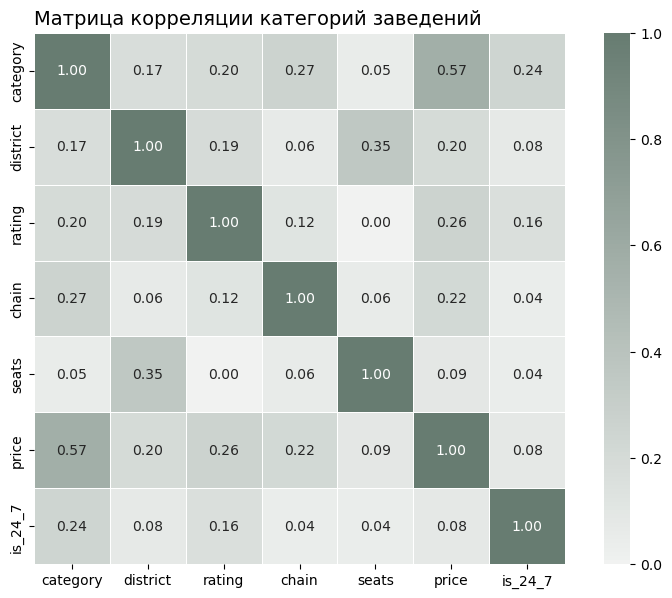

In [78]:
# Визуализируем матрицу корреляции
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    data=df_corr_matrix,
    cmap=my_cmap_corr,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=.5,
    square=True,
    ax=ax
)

ax.set_title('Матрица корреляции категорий заведений', loc='left', fontsize=14)

fname_png = "corr_matrix.png"
fname_pdf = "corr_matrix.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.tight_layout()
plt.show()

In [79]:
# Выведим показатели для связи raiting и price (показатель корреляции самый сильный - 0.26)
df_rat_price = df_rest_merge.groupby('price')['rating'].agg(['count', 'mean', 'median']).sort_values(by='mean')

file_path = temp_dir / 'df_rat_price.csv'
df_rat_price.reset_index().to_csv(file_path)

df_rat_price

,count,mean,median
price,,,
низкие,156,4.173077,4.2
средние,2117,4.297874,4.3
выше среднего,564,4.386348,4.4
высокие,478,4.436611,4.4


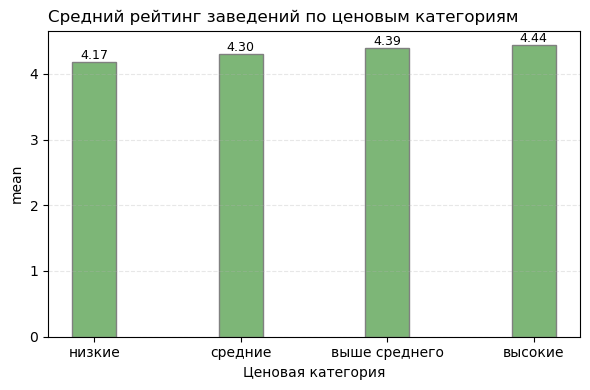

In [80]:
# Строим графики по категориям заведений
fig, ax = plt.subplots(figsize=(6, 4))

col_name = 'mean'
values = df_rat_price[col_name]

bars = ax.bar(df_rat_price.index, values, color='#7DB677', edgecolor='gray', width=0.3)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height * 1.00,
        f'{height:.2f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

ax.set_xlabel('Ценовая категория')
ax.set_ylabel(col_name)
ax.set_title('Средний рейтинг заведений по ценовым категориям', loc='left')
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()

fname_base = 'rat_price'
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()

<a id='conc_task_6'></a>

#### Выводы по задаче 6. Корреляция рейтингов заведений с прочими данными

1. **Наиболее заметная, но слабая связь с рейтингом:**
   * Согласно матрице корреляций, наибольший коэффициент связи с рейтингом (`rating`) наблюдается у ценовой категории (`price`) — **0.26**.
   * Поскольку значение далеко от 1.0, цену нельзя считать определяющим или единственным фактором, формирующим рейтинг заведения. Связь оценивается как слабая.
   * Остальные признаки имеют еще меньшую корреляцию с рейтингом: район (`district`) — 0.20, категория (`category`) — 0.20, круглосуточность (`is_24_7`) — 0.16, сетевой статус (`chain`) — 0.12. С количеством мест (`seats`) связь и вовсе отсутствует (0.00).

2. **Тенденция роста рейтинга с увеличением ценового сегмента:**
   * Несмотря на слабую корреляцию, прослеживается четкий тренд: чем выше ценовая категория, тем выше средний рейтинг заведения.
   * **Низкие цены:** средний рейтинг **4.17** (медиана 4.20), выборка — 156 заведений.
   * **Средние цены:** средний рейтинг **4.30** (медиана 4.30), выборка — 2117 заведений.
   * **Выше среднего:** средний рейтинг **4.39** (медиана 4.40), выборка — 564 заведения.
   * **Высокие цены:** средний рейтинг **4.44** (медиана 4.40), выборка — 478 заведений.

3. **Дополнительные наблюдения из матрицы корреляций:**
   * Самая сильная связь во всей матрице наблюдается между категорией заведения и ценой (`category` и `price`) — **0.57**.
   * Также заметна связь между районом и количеством мест (`district` и `seats`) — **0.35**.

**Вывод:** 
Более дорогие заведения в среднем имеют более высокий рейтинг (рост с 4.17 до 4.44 балла). Однако из-за слабой силы связи (0.26) высокий чек не гарантирует отличных оценок. Рейтинг заведения формируется совокупностью факторов, среди которых цена играет не главенствующую роль.

[Вернуться к разделу 'Исследовательский анализ данных'](#data_analysis)

[Вернуться в начало](#beginning)

<a id='task_7'></a>

### **Задача 7. ТОП-15 популярных сетей в Москве**

Сгруппируйте данные по названиям заведений и найдите топ-15 популярных сетей в Москве. Для них посчитайте значения среднего рейтинга. Под популярностью понимается количество заведений этой сети в регионе. К какой категории заведений они относятся? Результат сопроводите подходящими визуализациями.

In [81]:
# Создадим датафрейм с только сетевыми заведениями
df_rest_chain = df_rest_merge[df_rest_merge['chain'] == 1].copy()

path_file = processed_dir / 'rest_chain.csv'
df_rest_chain.to_csv(path_file)

In [82]:
# Определяем ТОП-15 популярных сетей
df_top_15 = df_rest_chain.groupby('name').agg(
    company=('id', 'count'),
    avg_rating=('rating', 'mean'),
    category=('category', 'unique')
).sort_values('company', ascending=False).head(15)

df_top_15 = df_top_15.reset_index()
df_top_15['name'] = df_top_15['name'].str.replace('кулинарная лавка братьев караваевых', 'лавка братьев к.')
df_top_15 = df_top_15.set_index('name')

file_path = temp_dir / 'df_top_15.csv'
df_top_15.to_csv(file_path)

df_top_15

,company,avg_rating,category
name,,,
шоколадница,120,4.177500,"[кофейня, кафе]"
домино'с пицца,76,4.169737,[пиццерия]
додо пицца,74,4.286487,[пиццерия]
one price coffee,71,4.064789,[кофейня]
яндекс лавка,69,3.872464,[ресторан]
cofix,65,4.075385,[кофейня]
prime,50,4.116000,"[ресторан, кафе]"
хинкальная,44,4.322727,"[быстрое питание, кафе, ресторан, столовая, ба..."
кофепорт,42,4.147619,[кофейня]


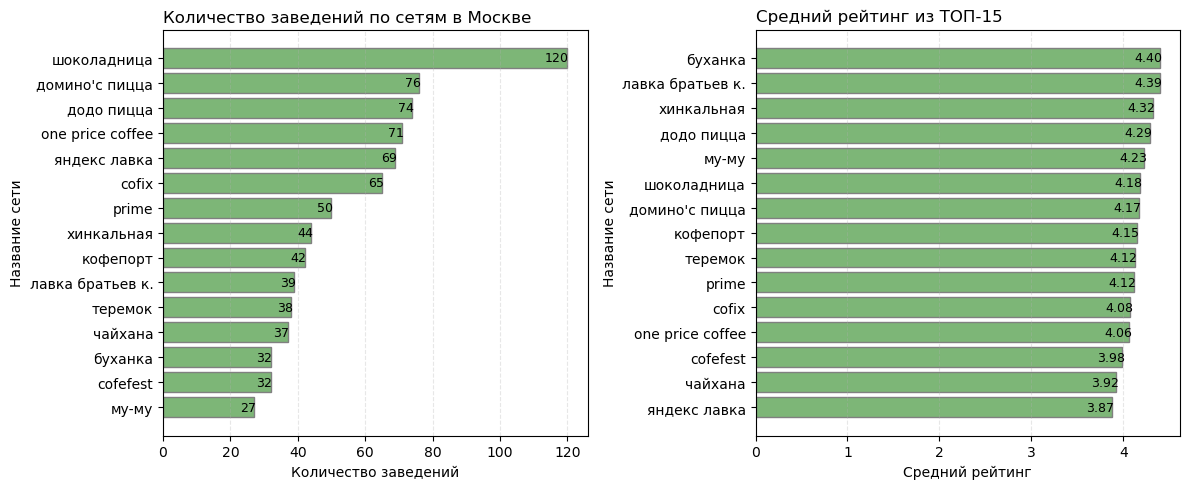

In [83]:
# Строим графики для количества и среднего рейтинга по сетям Москвы
cols = ['company', 'avg_rating']

titles = {
    'company': 'Количество заведений по сетям в Москве',
    'avg_rating': 'Средний рейтинг из ТОП‑15'
}

xlabels = {
    'company': 'Количество заведений',
    'avg_rating': 'Средний рейтинг'
}

fig, axs = plt.subplots(1, len(cols), figsize=(12, 5))
if len(cols) == 1:
    axs = [axs]

for ax, col in zip(axs, cols):
    if col == 'company':
        agg = df_top_15.sort_values(col, ascending=True)[col]
        bars = ax.barh(agg.index, agg.values, color='#7DB677', edgecolor='gray')
        for bar in bars:
            width = bar.get_width()
            ax.text(
                width + 0.5,
                bar.get_y() + bar.get_height() / 2,
                f'{width:.0f}',
                ha='right',
                va='center',
                fontsize=9
            )

    else:
        agg = df_top_15.sort_values(col, ascending=True)[col]
        bars = ax.barh(agg.index, agg.values, color='#7DB677', edgecolor='gray')
        for bar in bars:
            width = bar.get_width()
            ax.text(
                width + 0.03,
                bar.get_y() + bar.get_height() / 2,
                f'{width:.2f}',
                ha='right',
                va='center',
                fontsize=9
            )

    ax.set_title(titles[col], loc='left')
    ax.set_xlabel(xlabels[col])
    ax.set_ylabel('Название сети')
    ax.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()

fname_base = "_".join(cols)
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()

<a id='conc_task_7'></a>

#### Выводы по задаче 7. ТОП-15 популярных сетей в Москве

1. **Сформирован топ-15 сетей по количеству заведений.**  
   В выборке определены 15 наиболее представленных сетей Москвы. Лидером является **«Шоколадница»** — **120 заведений**. Далее следуют:
   - **«Домино’с Пицца»** — 76 заведений;
   - **«Додо Пицца»** — 74 заведения;
   - **«One Price Coffee»** — 71 заведение.

2. **Средние рейтинги сетей из топ-15 находятся в диапазоне примерно от 3,87 до 4,40.**  
   - Самый высокий средний рейтинг — у **«Буханки»**: около **4,40**.
   - Самый низкий средний рейтинг — у **«Яндекс Лавки»**: около **3,87**.
   - Большинство сетей из топ-15 имеют средний рейтинг выше **4,0**, что говорит о достаточно высоком уровне оценок.

3. **В топ-15 преобладают сети в категориях «кафе», «кофейня» и «ресторан».**  
   Также заметную часть составляют специализированные сети, например пиццерии **«Домино’с Пицца»** и **«Додо Пицца»**. Некоторые сети представлены сразу в нескольких категориях заведений, например **«Шоколадница»** — в категориях «кофейня» и «кафе», **«Хинкальная»** — в нескольких форматах, **«Му-Му»** — также в нескольких категориях.

4. **Количество заведений сети и её средний рейтинг не связаны напрямую.**  
   Наиболее популярная по числу заведений сеть **«Шоколадница»** не имеет самого высокого среднего рейтинга. При этом менее распространённые сети, например **«Буханка»** и **«Лавка братьев К.»**, демонстрируют более высокие средние оценки. Это означает, что масштаб сети не обязательно является определяющим фактором её среднего рейтинга.

5. **Вывод:**  
   На рынке Москвы среди топ-15 сетей лидирует **«Шоколадница»** по количеству заведений, однако по среднему рейтингу первое место занимает **«Буханка»**. Сетевой формат широко представлен в кафе, кофейнях и ресторанах, а также в пиццериях. При этом высокая представленность сети не гарантирует максимально высокий рейтинг.

[Вернуться к разделу 'Исследовательский анализ данных'](#data_analysis)

[Вернуться в начало](#beginning)

<a id='task_8'></a>

### **Задача 8. Вариация среднего чека в зависимости от района Москвы**

Изучите вариацию среднего чека заведения (столбец `middle_avg_bill`) в зависимости от района Москвы. Проанализируйте цены в центральном административном округе и других. Как удалённость от центра влияет на цены в заведениях? Результат сопроводите подходящими визуализациями.

In [84]:
# Выводим статистические данные по районам Москвы
df_rest_merge.groupby('district')['middle_avg_bill'].describe()

,count,mean,std,min,25%,50%,75%,max
district,,,,,,,,
ВАО,260.0,820.626953,850.903320,50.0,338.00,575.0,1100.0,10000.0
ЗАО,306.0,1053.225464,779.008484,50.0,427.50,1000.0,1500.0,5250.0
САО,322.0,927.959656,912.609192,130.0,350.00,650.0,1250.0,11000.0
СВАО,301.0,716.611267,591.232117,50.0,325.00,500.0,950.0,4500.0
СЗАО,157.0,822.222900,595.055237,120.0,340.00,700.0,1100.0,2900.0
ЦАО,1060.0,1191.057495,920.014709,0.0,500.00,1000.0,1500.0,7250.0
ЮАО,314.0,834.398071,2008.640625,100.0,350.00,500.0,1037.5,35000.0
ЮВАО,194.0,654.097961,566.825684,30.0,281.25,450.0,887.5,3750.0
ЮЗАО,235.0,792.561707,559.173096,100.0,350.00,600.0,1100.0,2750.0


In [85]:
# Создадим новый столбец с принадлежностью к ЦАО
df_rest_merge['is_cad'] = df_rest_merge['district'] == 'ЦАО'

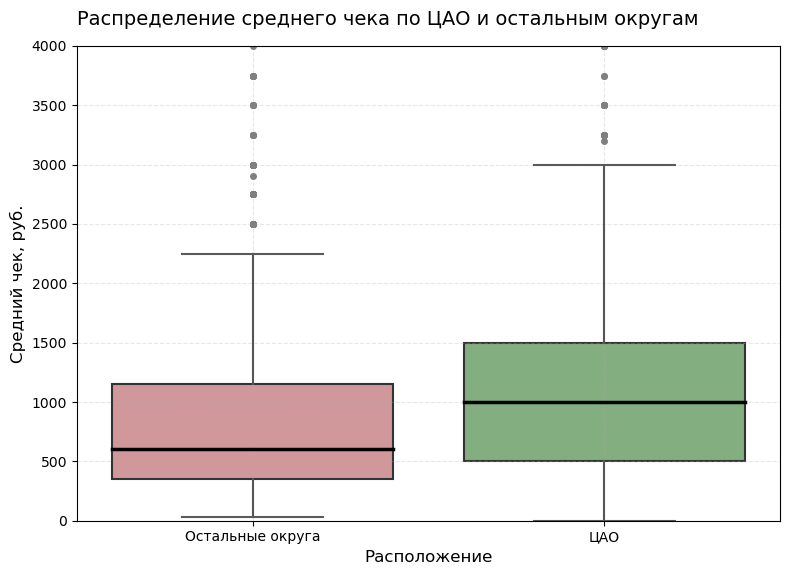

In [86]:
# Строим диаграммы размаха для распределения среднего чека в ЦАО и осталных районов
# Настройка стиля: белый фон с серой пунктирной сеткой (как на фото)
fig, ax = plt.subplots(figsize=(8, 6))

ax = sns.boxplot(
    data=df_rest_merge,
    x='is_cad',
    y='middle_avg_bill',
    palette=['#DB8E92', '#7DB677'],
    whiskerprops=dict(linewidth=1.5, color='#555555'),
    boxprops=dict(linewidth=1.5, edgecolor='#333333'),
    medianprops=dict(color='black', linewidth=2.5),
    flierprops=dict(marker='o', markersize=4, markerfacecolor='gray', markeredgecolor='gray')
)

plt.title('Распределение среднего чека по ЦАО и остальным округам', fontsize=14, pad=15, loc='left')
plt.xlabel('Расположение', fontsize=12)
plt.ylabel('Средний чек, руб.', fontsize=12)

ax.set_xticklabels(['Остальные округа', 'ЦАО'])
plt.ylim(0, 4000)
plt.suptitle('')
ax.grid(axis='both', alpha=0.3,linestyle='--')

plt.tight_layout()

fname_base = 'is_cad_boxplot'
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()

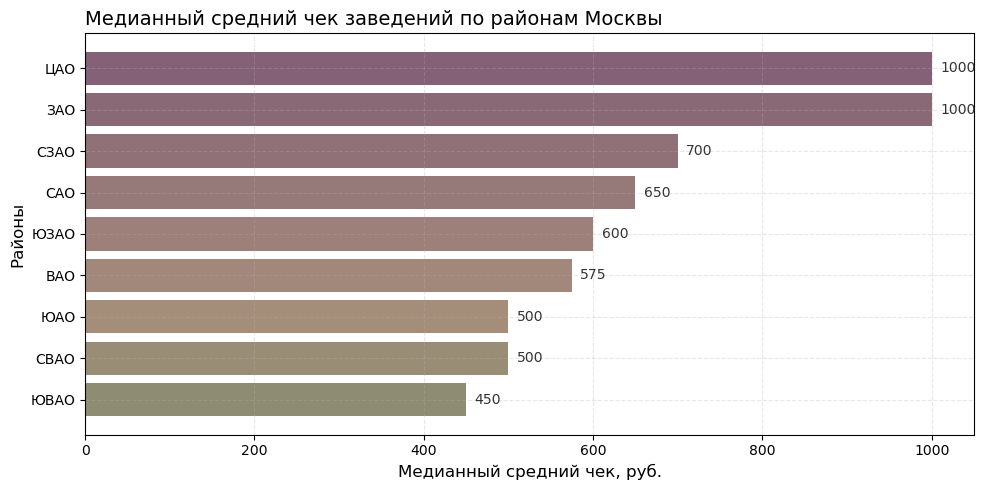

In [87]:
# Считаем медианный чек по районам
median_by_district = (
    df_rest_merge.groupby('district')['middle_avg_bill']
    .median()
    .sort_values(ascending=True)
)

districts = median_by_district.index.tolist()
values = median_by_district.values
n_cats = len(districts)
indices = np.linspace(0.3, 1.0, n_cats)
colors = [my_cmap_03(i) for i in indices]

# Создаём фигуру и оси
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    districts,
    values,
    color=colors
)

# Заголовок и подписи осей
ax.set_title('Медианный средний чек заведений по районам Москвы', loc='left', fontsize=14)
ax.set_xlabel('Медианный средний чек, руб.', fontsize=12)
ax.set_ylabel('Районы', fontsize=12)
ax.grid(axis='both', alpha=0.3,linestyle='--')

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 10,
        bar.get_y() + bar.get_height() / 2,
        f'{width:.0f}',
        va='center',
        fontsize=10,
        color='#333333'
    )


plt.tight_layout()

fname_base = 'dist_barh'
fname_png = f"{fname_base}.png"
fname_pdf = f"{fname_base}.pdf"

fig.savefig(png_dir / fname_png, dpi=300, bbox_inches="tight", pad_inches=0.1)
fig.savefig(pdf_dir / fname_pdf, bbox_inches="tight", pad_inches=0.1)

plt.show()

#### Выводы по анализу среднего чека в разрезе районов Москвы

1. **Лидеры и аутсайдеры по медианному чеку:**
   * Наиболее высокий медианный средний чек зафиксирован в **Центральном (ЦАО)** и **Западном (ЗАО)** административных округах — **1000 ₽**.
   * В остальных округах медианный чек ниже и варьируется от **450 ₽** в Юго-Восточном административном округе (ЮВАО) до **700 ₽** в Северо-Западном административном округе (СЗАО).
   * Промежуточные позиции занимают САО (650 ₽), ЮЗАО (600 ₽), ВАО (575 ₽), ЮАО и СВАО (по 500 ₽).

2. **Сравнение ЦАО с остальными округами:**
   * Центральный административный округ выделяется на фоне остальных. Согласно диаграмме размаха, медианный чек в ЦАО составляет **1000 ₽**, в то время как в остальных округах он находится на уровне около **600 ₽**.
   * Также в ЦАО наблюдается более широкий интерквартильный размах (от 500 до 1500 ₽), что говорит о большем разнообразии цен и высокой концентрации заведений премиального сегмента.
   * Высокие цены в центре логично объясняются более высокой стоимостью аренды и особенностями спроса .

3. **Наличие выбросов и выбор метрики:**
   * В данных присутствуют значительные выбросы. Например, максимальное значение среднего чека в **ЮАО** достигает **35 000 ₽**, что сильно искажает среднее арифметическое (834 ₽ при медиане 500 ₽).
   * Из-за сильной правосторонней асимметрии и аномальных значений для сравнения округов был выбран **медианный** средний чек.

4. **Ограничения анализа:**
   * Несмотря на очевидный тренд (в центре дороже), нельзя утверждать, что средний чек строго снижается по мере удаления от центра. 
   * В данных отсутствует точное расстояние каждого заведения от центра, а между округами наблюдаются свои локальные особенности (например, ЗАО входит в число лидеров, а ЮЗАО уступает САО).

**Вывод:** 
Расположение заведения в Москве тесно связано с уровнем цен. Центральный административный округ является самым дорогим по медианному среднему чеку, а также лидирует по разнообразию ценовых предложений. Однако утверждать, что средний чек строго снижается по мере удаления от центра, нельзя.

[Вернуться к разделу 'Исследовательский анализ данных'](#data_analysis)

[Вернуться в начало](#beginning)

<a id='conclusion'></a>

## Итоговый вывод и рекомендации

### 1. Общий обзор проделанной работы

В рамках проекта были проанализированы данные о заведениях общественного питания Москвы, собранные летом 2022 года. Источники с информацией о характеристиках заведений и ценах были объединены; дополнительно проведены проверка качества данных, обработка пропусков и анализ дубликатов.

В ходе исследовательского анализа рассматривались категории заведений, их распределение по административным округам, сетевой статус, количество посадочных мест, рейтинги, ценовые категории, популярность сетей и средний чек.

### 2. Ответы на исследовательские вопросы

- В Москве чаще всего встречаются кафе, рестораны и кофейни. Наибольшая концентрация заведений и наиболее широкое разнообразие категорий наблюдаются в Центральном административном округе; этот округ также является самым конкурентным.
- Среди заведений больше несетевых, чем сетевых: 61,9% против 38,1%. При этом сетевой формат особенно характерен для кофеен, пиццерий и булочных.
- Количество посадочных мест сильно варьируется, медиана составляет 75 мест; в данных есть заметные выбросы. Наиболее высокие типичные значения посадочных мест наблюдаются у ресторанов, баров и пабов, а также у кофеен.
- Средние рейтинги заведений всех категорий находятся на высоком уровне — примерно от 4,0 до 4,4 балла. Самый высокий средний рейтинг у баров и пабов, самый низкий — у заведений быстрого питания. Наиболее заметная из исследованных связей — связь рейтинга с ценовой категорией, однако она слабая.
- Среди сетевых заведений наиболее популярны «Шоколадница», «Домино'с Пицца», «Додо Пицца» и One Price Coffee. При этом большое количество точек сети не гарантирует более высокий рейтинг: явной прямой зависимости между числом заведений и средней оценкой не обнаружено.
- Наиболее высокий медианный средний чек — 1000 ₽ — наблюдается в Центральном и Западном административных округах; в большинстве остальных округов он ниже. Это позволяет предположить связь центрального расположения с более высоким уровнем цен. Однако прямую зависимость цены от расстояния до центра установить нельзя, поскольку фактическое расстояние до центра в исходных данных отсутствует.
- Таким образом, при выборе места для нового заведения следует учитывать не только число конкурентов, но и особенности конкретного округа, категорию заведения, ценовой сегмент и формат бизнеса.

### 3. Рекомендации на основе анализа данных

- Для открытия нового заведения можно рассмотреть формат кафе или кофейни: эти категории широко распространены и пользуются спросом, но из-за большого числа заведений конкуренция в них будет высокой.
- Не стоит ориентироваться исключительно на Центральный административный округ. В ЦАО много потенциальных клиентов и высокий средний чек, но также высока концентрация конкурентов.
- Перспективным может быть район за пределами ЦАО с достаточным количеством потенциальных клиентов и меньшей конкуренцией. При выборе важно учитывать категорию заведения и ценовой сегмент: более доступный формат может быть ориентирован на округа с низким медианным чеком, а более высокое ценовое позиционирование — на ЦАО или Западный административный округ.
- Для нового проекта также можно рассмотреть сетевой формат, особенно если концепция связана с кофейней, пиццерией или булочной: в этих категориях сетевые заведения представлены особенно активно.
- Окончательное решение о месте и концепции рекомендуется принимать после дополнительного анализа конкретных локаций: плотности конкурентов в радиусе, транспортной доступности, пешеходного трафика, арендной ставки и характеристик целевой аудитории.

[Вернуться в начало](#beginning)